Universidade do Vale do Itajaí<br>
Escola Politécnica<br>
Processamento Digital de Sinais: Imagens<br>
Aluno(s): Hérick Vitor Vieira Bittencourt, Lucas Toller Gutmann e Pablo Henrique Blayne Alcantara

# Exercício Avaliativo - Filtragem na Frequência e Segmentação
## Caracteres com falhas: filtros passa-baixa ideal, Butterworth e gaussiano

Nesta atividade, investigaremos como a filtragem passa-baixa no domínio da frequência influencia a segmentação de caracteres degradados. A imagem base é a [`Fig0907(a)(text_gaps_1_and_2_pixels).tif`](https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/Fig0907(a)(text_gaps_1_and_2_pixels).tif). A análise deverá responder a duas perguntas:

- Como Otsu, k-means e Canny representam os caracteres e suas falhas?
- Quanto a filtragem contribui para reduzir falhas indesejadas nos traços após a segmentação?

Consideramos falhas indesejadas as pequenas lacunas ou interrupções em regiões que deveriam pertencer ao traço de um caractere. Os espaços internos próprios das letras, como em “a”, “o” e “e”, devem ser preservados. Serão comparados os filtros ideal, Butterworth e gaussiano. Para cada configuração, avalie a redução das falhas e os possíveis efeitos negativos: engrossamento ou apagamento de traços, perda de espaços internos e união de caracteres próximos. 

A imagem sem filtragem será a referência de comparação do processamento: cada método deverá ser aplicado tanto à entrada original degradada quanto às versões filtradas. Não há garantia de que a filtragem melhore todos os resultados; conclusões de melhora ou piora devem ser sustentadas pelas figuras e métricas. Não utilize operações morfológicas. A entrega deverá ser realizada neste notebook, com código executado, resultados visíveis e respostas às questões propostas.

### Preparação

In [1]:
# Preparação automática da imagem — VS Code e Google Colab

from pathlib import Path
from urllib.request import urlretrieve
import os

ARQUIVO = "Fig0907(a)(text_gaps_1_and_2_pixels).tif"

# Ajusta a pasta de execução quando o notebook é aberto
# a partir da raiz do repositório no VS Code.
if not (Path("data") / ARQUIVO).exists():
    pasta_m2 = Path("M2-1")
    if (pasta_m2 / "data" / ARQUIVO).exists():
        os.chdir(pasta_m2)

imagem = Path("data") / ARQUIVO

# Caso a imagem não exista, baixa a original do GitHub.
if not imagem.exists():
    print("Baixando imagem original...")
    imagem.parent.mkdir(parents=True, exist_ok=True)

    url = (
        "https://raw.githubusercontent.com/VielF/ColabProjects/"
        "main/dataset/OperacaoMorfologia/"
        "Fig0907%28a%29%28text_gaps_1_and_2_pixels%29.tif"
    )
    urlretrieve(url, imagem)

print("Imagem carregada:", imagem.resolve())

Imagem carregada: C:\Users\lucas\Downloads\processamento-imagens-main\M2-1\data\Fig0907(a)(text_gaps_1_and_2_pixels).tif


In [2]:
#%pip install numpy scipy matplotlib pillow scikit-image scikit-learn pandas
import base64, io, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
from scipy.ndimage import label, distance_transform_edt
from skimage.filters import threshold_otsu
from skimage.feature import canny
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from sklearn.cluster import KMeans
from IPython.display import display

In [3]:
def painel(imagens, titulos, colunas=3, figsize=None):
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=figsize or (4*colunas, 3.3*linhas), squeeze=False)
    for ax, im, titulo in zip(axs.flat, imagens, titulos):
        ax.imshow(im, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        ax.set_title(titulo); ax.axis('off')
    for ax in list(axs.flat)[len(imagens):]: ax.axis('off')
    fig.tight_layout(); plt.show()

def mostrar_recorte(imagem, x, y, largura, altura, tamanho=(10, 5)):
    recorte = imagem[y:y + altura, x:x + largura]

    plt.figure(figsize=tamanho)
    plt.imshow(recorte, cmap='gray', interpolation='nearest')
    plt.title('Recorte ampliado')
    plt.axis('off')
    plt.show()

    return recorte

### Carregamento e análise da imagem

1. Identificação das falhas e seleção dos recortes: Inspecione a imagem ampliada e selecione pelo menos três recortes:

- Uma região com falhas indesejadas nos traços.
- Uma região com espaços internos legítimos dos caracteres.
- Uma região com caracteres próximos, sujeitos à união após a filtragem.

Registre as coordenadas e utilize os mesmos recortes em todas as comparações. Marque as falhas que pretende reduzir e as estruturas que devem ser preservadas. Não considere todo pixel de fundo no interior de uma letra como defeito.

Dimensões: (444, 508)
Valores presentes: [0. 1.] | pixels de texto: 7.9%


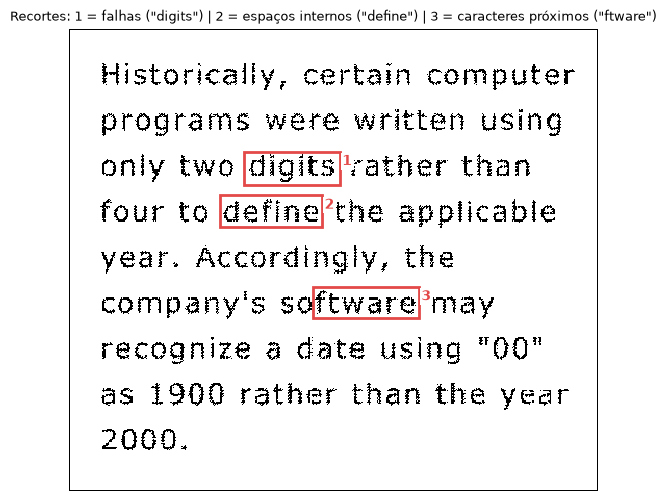

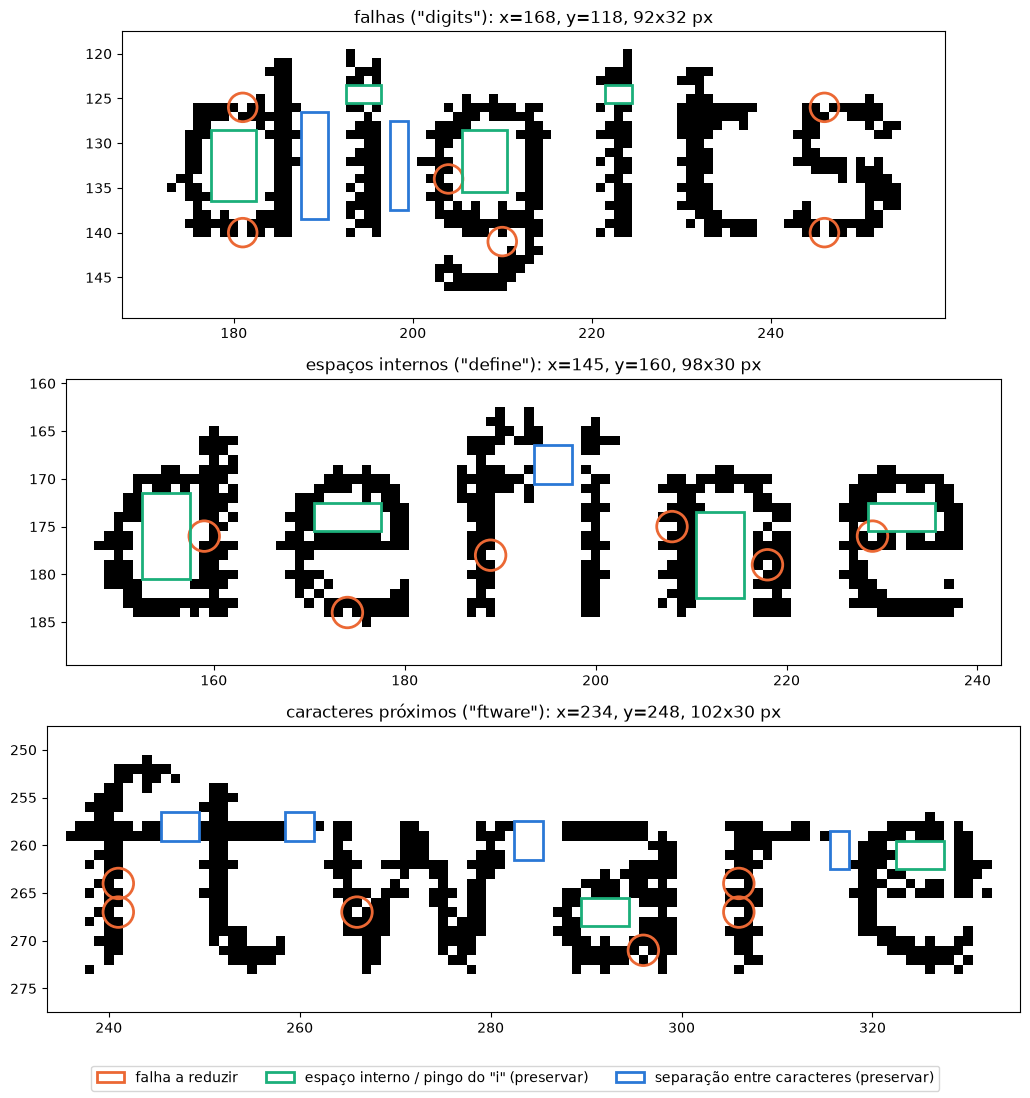

In [4]:
"""CARREGAMENTO DA IMAGEM E SELEÇÃO DOS RECORTES"""
import matplotlib.patches as mpatches

# Inverte imagem .tif para texto escuro (0) e fundo claro (1)
original = 1.0 - np.asarray(Image.open('data/Fig0907(a)(text_gaps_1_and_2_pixels).tif'), dtype=float)
print('Dimensões:', original.shape)
print(f'Valores presentes: {np.unique(original)} | pixels de texto: {np.mean(original == 0):.1%}')

# Recortes fixos (x, y, largura, altura), usados em todas as comparações
#   falhas:    pontos (x, y) de lacunas indesejadas nos traços -> devem passar a ser texto
#   preservar: retângulos (x, y, l, a) de espaços internos e do pingo do "i" -> devem continuar fundo
#   separacao: retângulos entre caracteres vizinhos -> devem continuar fundo
RECORTES = {
    'falhas ("digits")': dict(
        caixa=(168, 118, 92, 32),
        falhas=[(181, 126), (181, 140), (204, 134), (210, 141), (246, 126), (246, 140)],
        preservar=[(178, 129, 5, 8), (206, 129, 5, 7), (193, 124, 4, 2), (222, 124, 3, 2)],
        separacao=[(188, 127, 3, 12), (198, 128, 2, 10)]),
    'espaços internos ("define")': dict(
        caixa=(145, 160, 98, 30),
        falhas=[(159, 176), (174, 184), (189, 178), (208, 175), (218, 179), (229, 176)],
        preservar=[(153, 172, 5, 9), (171, 173, 7, 3), (229, 173, 7, 3), (211, 174, 5, 9)],
        separacao=[(194, 167, 4, 4)]),
    'caracteres próximos ("ftware")': dict(
        caixa=(234, 248, 102, 30),
        falhas=[(241, 264), (241, 267), (266, 267), (296, 271), (306, 264), (306, 267)],
        preservar=[(290, 266, 5, 3), (323, 260, 5, 3)],
        separacao=[(246, 257, 4, 3), (259, 257, 3, 3), (283, 258, 3, 4), (316, 259, 2, 4)]),
}
CORES = {'falhas': '#eb6834', 'preservar': '#1baf7a', 'separacao': '#2a78d6'}

def recortar(imagem, caixa):
    x, y, largura, altura = caixa
    return imagem[y:y + altura, x:x + largura]

def desenhar_marcas(ax, r):
    """Desenha as marcas em coordenadas absolutas (o eixo precisa usar o extent da caixa)."""
    for x, y in r['falhas']:
        ax.add_patch(mpatches.Circle((x, y), 1.6, fill=False, ec=CORES['falhas'], lw=2))
    for tipo in ('preservar', 'separacao'):
        for x, y, l, a in r[tipo]:
            ax.add_patch(mpatches.Rectangle((x - .5, y - .5), l, a, fill=False, ec=CORES[tipo], lw=2))

# Visão geral com a posição dos recortes
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(original, cmap='gray', vmin=0, vmax=1, interpolation='nearest')
for k, (nome, r) in enumerate(RECORTES.items(), 1):
    x, y, l, a = r['caixa']
    ax.add_patch(mpatches.Rectangle((x - .5, y - .5), l, a, fill=False, ec='#e34948', lw=2))
    ax.text(x + l + 2, y + 2, str(k), color='#e34948', fontsize=10, fontweight='bold', va='top',
            bbox=dict(fc='white', ec='none', pad=1))
ax.set_title('Recortes: ' + ' | '.join(f'{k} = {nome}' for k, nome in enumerate(RECORTES, 1)), fontsize=9)
ax.axis('off')
plt.show()

# Recortes ampliados com as marcas (eixos em coordenadas da imagem)
fig, axs = plt.subplots(3, 1, figsize=(12, 11))
for ax, (nome, r) in zip(axs, RECORTES.items()):
    x, y, l, a = r['caixa']
    ax.imshow(recortar(original, r['caixa']), cmap='gray', vmin=0, vmax=1, interpolation='nearest',
              extent=(x - .5, x + l - .5, y + a - .5, y - .5))
    desenhar_marcas(ax, r)
    ax.set_title(f'{nome}: x={x}, y={y}, {l}x{a} px')
legenda = [mpatches.Patch(fill=False, ec=CORES['falhas'], lw=2, label='falha a reduzir'),
           mpatches.Patch(fill=False, ec=CORES['preservar'], lw=2, label='espaço interno / pingo do "i" (preservar)'),
           mpatches.Patch(fill=False, ec=CORES['separacao'], lw=2, label='separação entre caracteres (preservar)')]
fig.legend(handles=legenda, loc='lower center', ncol=3)
fig.tight_layout(rect=(0, 0.04, 1, 1)); plt.show()

**Resposta**

| Recorte | (x, y, largura, altura) | O que mostra |
|---|---|---|
| 1. falhas ("digits") | (168, 118, 92, 32) | lacunas de 1–2 px no topo e na base do "d", na lateral e na cauda do "g", no topo e na base do "s" |
| 2. espaços internos ("define") | (145, 160, 98, 30) | olho do "d", olhos pequenos (3–4 px de altura) dos dois "e" e abertura do "n" |
| 3. caracteres próximos ("ftware") | (234, 248, 102, 30) | barras do "f" e do "t" a 4 px uma da outra; "t"–"w", "w"–"a" e "r"–"e" a 2–3 px |

- **Círculos laranja:** falhas que devem virar texto.
- **Retângulos verde-água:** espaços internos e o espaço entre o pingo e a haste do "i", que devem continuar fundo.
- **Retângulos azuis:** separações entre caracteres vizinhos, que também devem continuar fundo.

Observação: As falhas têm 1–2 px, e algumas estruturas legítimas têm quase a mesma largura, o espaço do pingo do "i" e a separação "r"–"e" tem 2 px, e o olho do "e" tem 3–4 px. Por isso, nem todo fundo cercado por texto é defeito, e um filtro que feche lacunas de 2 px tende a fechar também esses espaços.

### Filtragem passa-baixa no domínio da frequência


#### Relação entre o raio do filtro e a frequência de corte

Para embasar vocês, no exercício sobre filtragem na frequência (mais especificamente nas funções) o parâmetro `radius` representa a distância ao centro do espectro, medida em posições da matriz da FFT. Esse raio corresponde ao parâmetro $D_0$ das equações dos filtros. Após aplicar `fftshift`, a frequência zero fica na posição central. Quanto mais distante desse centro, maior a frequência espacial representada.

##### Imagens quadradas

Para uma imagem de tamanho $N \times N$, cada posição da FFT corresponde a um incremento de $1/N$ ciclos por pixel. Assim, a relação entre o raio e a frequência de corte é:

$$
f_c = \frac{D_0}{N}
\qquad\Longleftrightarrow\qquad
D_0 = f_c \cdot N
$$

Nessa expressão:

- $f_c$ é a frequência de corte, em ciclos por pixel;
- $D_0$ é o raio, em posições da matriz da FFT;
- $N$ é o número de linhas ou colunas da imagem quadrada utilizada na FFT.

Por exemplo, para uma imagem de $512 \times 512$ e um raio de 35:

$$
f_c = \frac{35}{512} \approx 0{,}0684 \text{ ciclos/pixel}
$$

Portanto, a configuração `radius=35` corresponde a uma frequência de corte de aproximadamente $0{,}0684$ ciclos por pixel nessa imagem.

| Raio $D_0$ | Frequência de corte $f_c$ | Período espacial $T=1/f_c$ |
|---:|---:|---:|
| 16 | 0,03125 ciclos/pixel | 32 pixels/ciclo |
| 35 | 0,06836 ciclos/pixel | 14,63 pixels/ciclo |
| 64 | 0,125 ciclos/pixel | 8 pixels/ciclo |

O período indica o tamanho de um ciclo de uma oscilação espacial. Sendo assim, ele não representa diretamente a espessura de uma letra ou a largura de uma falha, com isso, letras, bordas e falhas contêm várias frequências.

##### Imagens retangulares

Em uma imagem com $M$ linhas e $N$ colunas, os incrementos de frequência são:

$$
\Delta f_y = \frac{1}{M}
\qquad\text{e}\qquad
\Delta f_x = \frac{1}{N}
$$

Consequentemente, um círculo de raio $D_0$ na matriz da FFT corresponde aos seguintes cortes nos eixos:

$$
f_{c,x} = \frac{D_0}{N}
\qquad\text{e}\qquad
f_{c,y} = \frac{D_0}{M}
$$

Quando $M \neq N$, esses valores são diferentes. Portanto, um círculo definido diretamente pelas posições da matriz não representa a mesma frequência de corte em todas as direções. Para definir uma frequência de corte radial em ciclos por pixel, podemos normalizar cada eixo pelas respectivas dimensões:

$$
D_f(r,c) =
\sqrt{
\left(\frac{r-r_c}{M}\right)^2 +
\left(\frac{c-c_c}{N}\right)^2
}
$$

Aqui, $(r_c,c_c)$ é o centro da FFT deslocada. Como $D_f$ está em ciclos por pixel, ele deve ser comparado diretamente com $f_c$. Nesse caso, não é necessário converter o corte para um raio inteiro. Se houver preenchimento da imagem antes da FFT, devem ser utilizadas as dimensões da matriz após esse preenchimento.

### Como escolher a frequência de corte?

A conversão entre raio e frequência é matemática, mas a escolha do melhor corte depende do objetivo do processamento. Para caracteres com pequenas falhas, podemos testar, por exemplo:

$$
f_c \in \{0{,}06;\ 0{,}10;\ 0{,}16;\ 0{,}24\}
$$

Em um filtro passa-baixa:

- Cortes menores produzem maior suavização, podendo reduzir pequenas descontinuidades, mas também apagar traços finos ou unir letras próximas.
- Cortes maiores preservam mais detalhes, mas podem manter ruído e falhas.

A comparação deve utilizar os mesmos recortes da imagem, observando tanto a saída filtrada quanto a máscara obtida após Otsu ou k-means. Uma aproximação entre traços na imagem suavizada pode se transformar em conexão somente após a segmentação. Quando existe uma referência íntegra, IoU e Dice ajudam a avaliar as máscaras de região. Sem essa referência, a escolha deve ser justificada pela análise visual, considerando recuperação das falhas, preservação dos traços e separação entre caracteres. Com isso, não existe uma conversão direta entre “falha de 2 pixels” e um único raio ideal. O resultado também depende da espessura dos traços, da proximidade entre letras, do tipo de filtro e do método de segmentação.

### O significado do corte em cada filtro

No filtro ideal, $D_0$ define uma separação abrupta: as frequências dentro do raio são preservadas e as externas são anuladas. No Butterworth e no gaussiano, a atenuação é gradual. Nas fórmulas usuais deste exercício, em $D=D_0$:

$$
H_{\text{Butterworth}}(D_0)=0{,}5
$$

$$
H_{\text{Gaussiano}}(D_0)=e^{-1/2}\approx0{,}607
$$

Assim, usar o mesmo raio nos três filtros não produz exatamente a mesma suavização.

### Centro do filtro

O centro deve corresponder à frequência zero após `fftshift`, definida pelas dimensões da matriz:

$$
r_c = \left\lfloor \frac{M}{2} \right\rfloor,
\qquad
c_c = \left\lfloor \frac{N}{2} \right\rfloor
$$

Na função `createPB` do exercício, o argumento `center` utiliza a ordem coluna e linha: `center=(cols//2, rows//2)`. A posição do maior pico do espectro não deve ser usada como regra para definir esse centro.

Seja $D=\sqrt{f_x^2+f_y^2}$, em **ciclos/pixel**, e $f_c>0$:

$$H_I(D)=\begin{cases}1&D\leq f_c\\0&D>f_c\end{cases},\quad
H_B(D)=\frac{1}{1+(D/f_c)^{2n}},\quad
H_G(D)=e^{-D^2/(2f_c^2)}.$$

O resultado é $g=\Re\{\mathcal F^{-1}[H\mathcal F(f)]\}$. Usamos `fftshift` para centralizar o espectro e `ifftshift` antes da inversa. O preenchimento por reflexão reduz o contato artificial entre bordas opostas; o recorte devolve o tamanho original. Tenha atenção, pois $f_c$ é um parâmetro de escala; os três filtros não têm o mesmo ganho em $D=f_c$. Butterworth tem ganho 0,5 e gaussiano aproximadamente 0,607. Comparar o mesmo $f_c$ não significa igualar toda a resposta espectral. O ideal pode produzir oscilações (*ringing*); o gaussiano suaviza a transição; a ordem controla a transição do Butterworth. Valores menores de $f_c$ suavizam mais. A filtragem não reconstrói de forma garantida informação perdida: a união pode surgir somente após o limiar, com risco de deformar letras.

2. Implemente os filtros ideal, Butterworth e gaussiano no domínio da frequência. Teste pelo menos duas frequências de corte por filtro e compare as ordens 1, 2 e 4 do Butterworth. Apresente as respostas dos filtros, os espectros antes e depois da filtragem e as imagens resultantes. Nos recortes selecionados, observe se a suavização aproxima os traços interrompidos e se também provoca perda de detalhes ou aproximação indevida entre caracteres. Explique as etapas da função e registre os parâmetros utilizados. Não substitua a filtragem na frequência por um filtro espacial.

**Dica**: utilize as funções disponibilizadas no exercícios sobre filtragem na frequência.

In [5]:
"""FILTROS PASSA-BAIXA NO DOMÍNIO DA FREQUÊNCIA"""

def criar_passa_baixa(shape, fc, tipo, n=2):
    """Cria um filtro passa-baixa do tipo especificado."""
    # PB do exercício usando a distância normalizada D_f (ciclos/pixel),
    # assim o corte é o mesmo nas linhas e colunas de uma imagem retangular.
    M, N = shape
    fy = np.fft.fftshift(np.fft.fftfreq(M))[:, None]
    fx = np.fft.fftshift(np.fft.fftfreq(N))[None, :]
    D = np.sqrt(fy**2 + fx**2)

    if tipo == 'ideal':
        return (D <= fc).astype(float)
    if tipo == 'butterworth':
        return 1.0 / (1.0 + (D / fc)**(2 * n))
    if tipo == 'gaussiano':
        return np.exp(-D**2 / (2 * fc**2))
    raise ValueError(f'Filtro desconhecido: {tipo}')


def filtrar_frequencia(imagem, fc, tipo, n=2):
    """g = Re{F^-1[H . F(f)]}. Retorna (g, F, H), com F e H da imagem já preenchida."""
    M, N = imagem.shape
    pm, pn = M // 2, N // 2

    # 1) Preenchimento por reflexão: a FFT trata a imagem como periódica, e a reflexão
    #    evita a descontinuidade artificial entre bordas opostas
    f = np.pad(imagem, ((pm, pm), (pn, pn)), mode='reflect')

    # 2) Espectro centralizado e filtro com as dimensões da matriz preenchida
    F = np.fft.fftshift(np.fft.fft2(f))
    H = criar_passa_baixa(f.shape, fc, tipo, n)

    # 3) Produto ponto a ponto e volta ao domínio espacial (ifftshift antes da inversa)
    g = np.real(np.fft.ifft2(np.fft.ifftshift(H * F)))

    # 4) Recorte para o tamanho original; o ringing do ideal sai de [0, 1], então saturamos
    g = np.clip(g[pm:pm + M, pn:pn + N], 0, 1)
    return g, F, H


# Configurações testadas: 4 cortes para cada filtro e ordens 1, 2 e 4 do Butterworth
CORTES = [0.06, 0.10, 0.16, 0.24]   # ciclos/pixel
ORDENS = [1, 2, 4]

CONFIGS = {'sem filtro': None}
for fc in CORTES:
    CONFIGS[f'ideal {fc:.2f}'] = dict(tipo='ideal', fc=fc)
    for n in ORDENS:
        CONFIGS[f'butter n={n} {fc:.2f}'] = dict(tipo='butterworth', fc=fc, n=n)
    CONFIGS[f'gauss {fc:.2f}'] = dict(tipo='gaussiano', fc=fc)

def aplicar_configs(imagem):
    """Retorna {configuração: imagem filtrada}, incluindo a entrada sem filtro como referência."""
    return {nome: imagem if p is None else filtrar_frequencia(imagem, **p)[0] for nome, p in CONFIGS.items()}

filtradas = aplicar_configs(original)

# Registro dos parâmetros: raio equivalente na matriz preenchida e escala espacial de cada corte
M, N = original.shape
Mp, Np = M + 2 * (M // 2), N + 2 * (N // 2)
print(f'Matriz da FFT após o preenchimento: {Mp} x {Np}')
display(pd.DataFrame({
    'fc (ciclos/pixel)': CORTES,
    'período 1/fc (px)': [1 / fc for fc in CORTES],
    'D0 nas linhas (fc·M)': [fc * Mp for fc in CORTES],
    'D0 nas colunas (fc·N)': [fc * Np for fc in CORTES],
    'σ espacial do gaussiano (px)': [1 / (2 * np.pi * fc) for fc in CORTES],
}).round(2))

Matriz da FFT após o preenchimento: 888 x 1016


,fc (ciclos/pixel),período 1/fc (px),D0 nas linhas (fc·M),D0 nas colunas (fc·N),σ espacial do gaussiano (px)
0,0.06,16.67,53.28,60.96,2.65
1,0.10,10.00,88.80,101.60,1.59
2,0.16,6.25,142.08,162.56,0.99
3,0.24,4.17,213.12,243.84,0.66


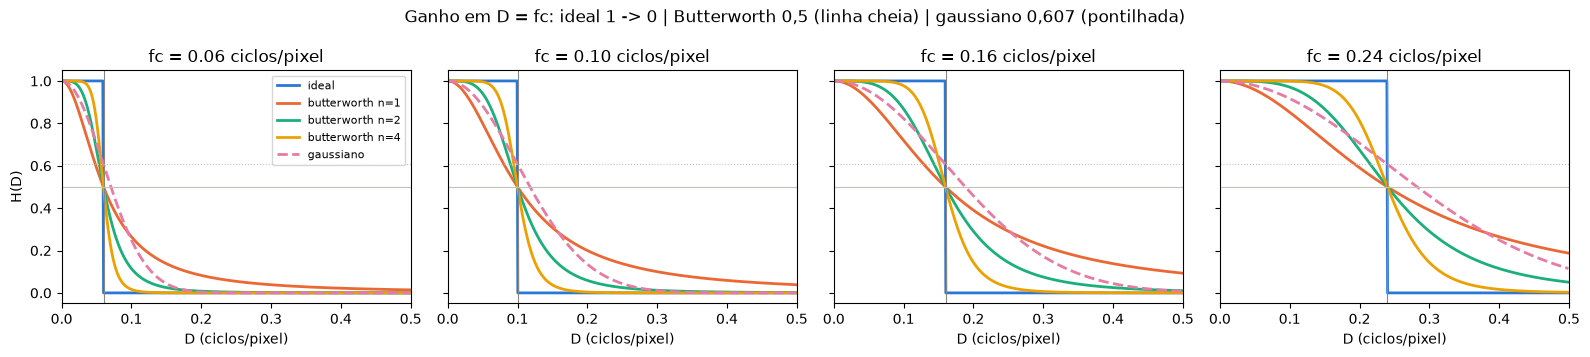

In [6]:
"""RESPOSTA DOS FILTROS: PERFIL RADIAL H(D)"""

# Linha central de H (do centro até a borda direita) = perfil radial ao longo do eixo fx
D = np.arange(Np - Np // 2) / Np
estilos = [('ideal', {}, '#2a78d6', '-'), ('butterworth', {'n': 1}, '#eb6834', '-'),
           ('butterworth', {'n': 2}, '#1baf7a', '-'), ('butterworth', {'n': 4}, '#eda100', '-'),
           ('gaussiano', {}, '#e87ba4', '--')]

fig, axs = plt.subplots(1, len(CORTES), figsize=(16, 3.6), sharey=True)
for ax, fc in zip(axs, CORTES):
    for tipo, extra, cor, ls in estilos:
        H = criar_passa_baixa((Mp, Np), fc, tipo, **extra)
        rotulo = tipo + (f' n={extra["n"]}' if extra else '')
        ax.plot(D, H[Mp // 2, Np // 2:], color=cor, ls=ls, lw=2, label=rotulo)
    ax.axvline(fc, color='#898781', lw=0.8)
    ax.axhline(0.5, color='#c3c2b7', lw=0.8); ax.axhline(np.exp(-0.5), color='#c3c2b7', lw=0.8, ls=':')
    ax.set_xlim(0, 0.5); ax.set_title(f'fc = {fc:.2f} ciclos/pixel'); ax.set_xlabel('D (ciclos/pixel)')
axs[0].set_ylabel('H(D)'); axs[0].legend(fontsize=8)
fig.suptitle('Ganho em D = fc: ideal 1 -> 0 | Butterworth 0,5 (linha cheia) | gaussiano 0,607 (pontilhada)')
plt.tight_layout(); plt.show()

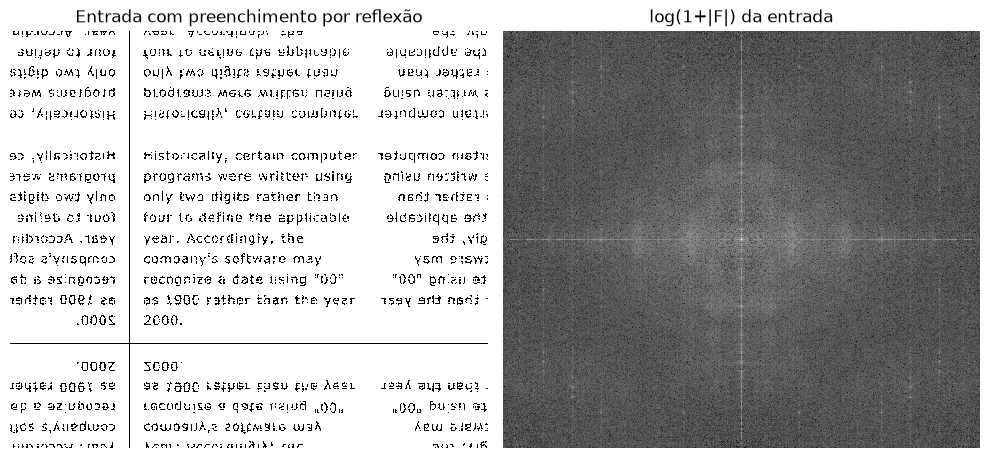

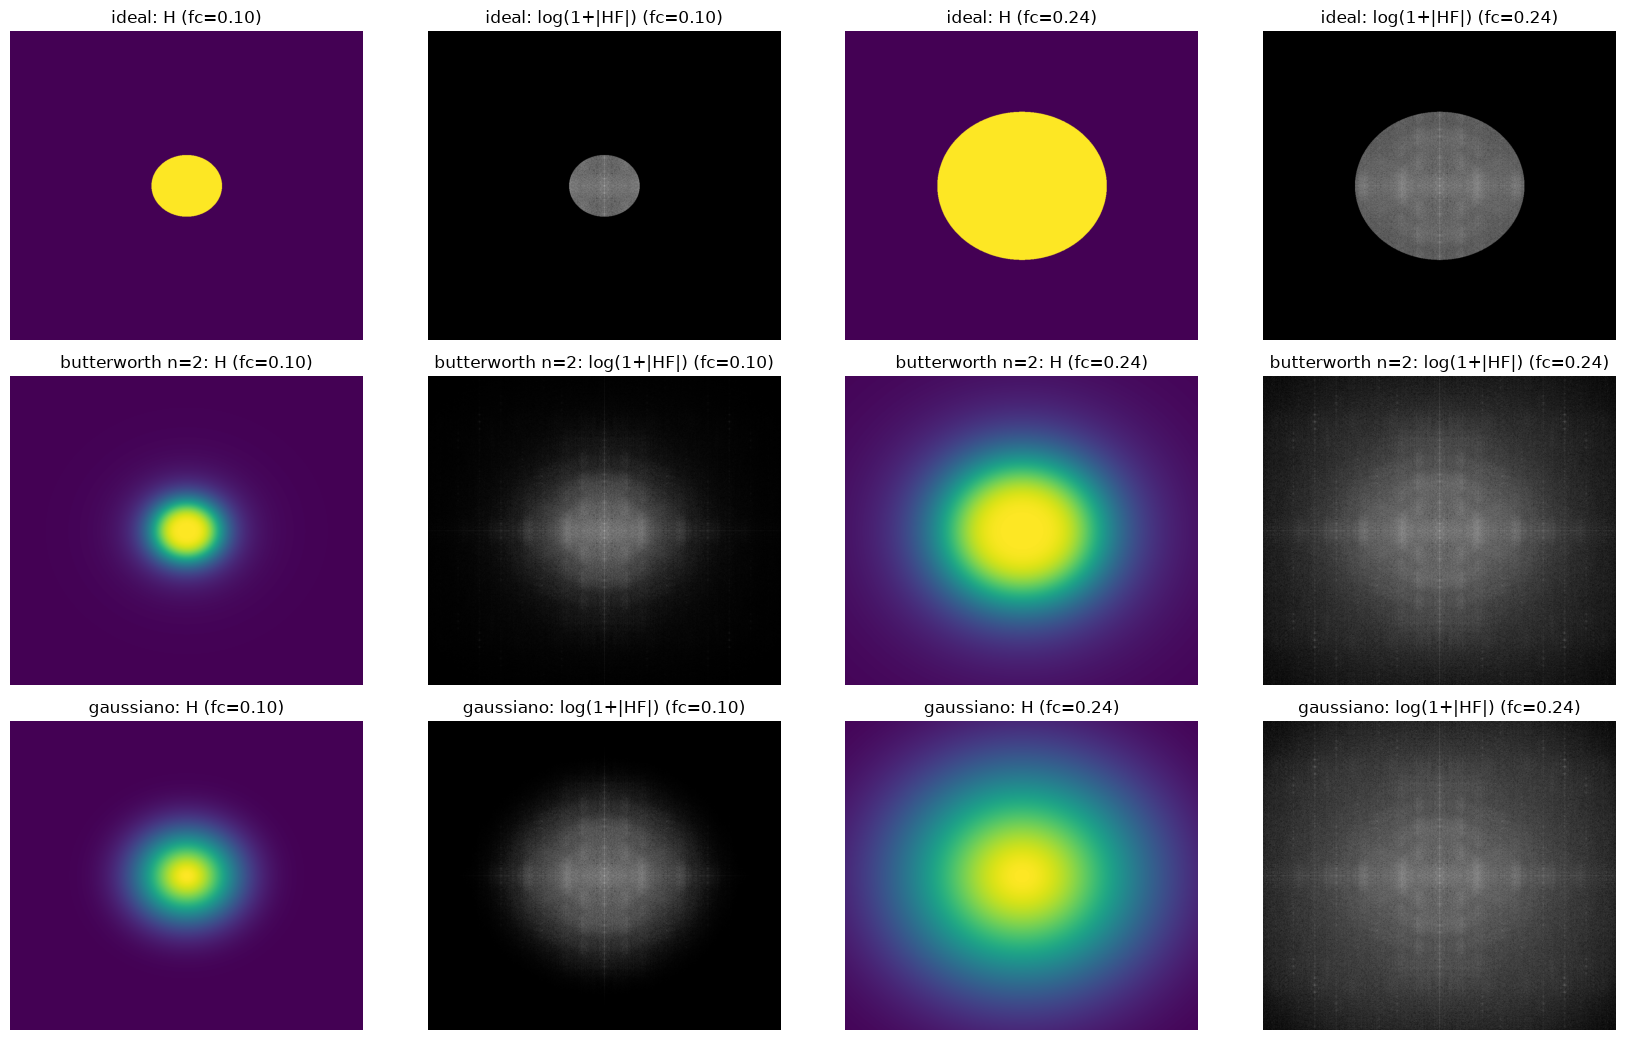

In [7]:
"""ESPECTROS ANTES E DEPOIS DA FILTRAGEM"""

# Entrada preenchida e seu espectro (o mesmo F é usado por todos os filtros)
preenchida = np.pad(original, ((M // 2, M // 2), (N // 2, N // 2)), mode='reflect')
_, F, _ = filtrar_frequencia(original, 0.10, 'ideal')
log_F = np.log1p(np.abs(F))
escala = log_F.max()   # mesma escala de cor para todos os espectros
painel([preenchida, log_F / escala], ['Entrada com preenchimento por reflexão', 'log(1+|F|) da entrada'], 2,
       figsize=(10, 4.5))

cortes_vistos = [0.10, 0.24]
filtros_vistos = [('ideal', {}), ('butterworth', {'n': 2}), ('gaussiano', {})]
fig, axs = plt.subplots(len(filtros_vistos), 2 * len(cortes_vistos), figsize=(17, 10.5))
for i, (tipo, extra) in enumerate(filtros_vistos):
    rotulo = tipo + (f' n={extra["n"]}' if extra else '')
    for j, fc in enumerate(cortes_vistos):
        H = criar_passa_baixa(F.shape, fc, tipo, **extra)
        axs[i, 2 * j].imshow(H, cmap='viridis', vmin=0, vmax=1)
        axs[i, 2 * j].set_title(f'{rotulo}: H (fc={fc:.2f})')
        axs[i, 2 * j + 1].imshow(np.log1p(np.abs(H * F)), cmap='gray', vmin=0, vmax=escala)
        axs[i, 2 * j + 1].set_title(f'{rotulo}: log(1+|HF|) (fc={fc:.2f})')
for ax in axs.flat: ax.axis('off')
plt.tight_layout(); plt.show()

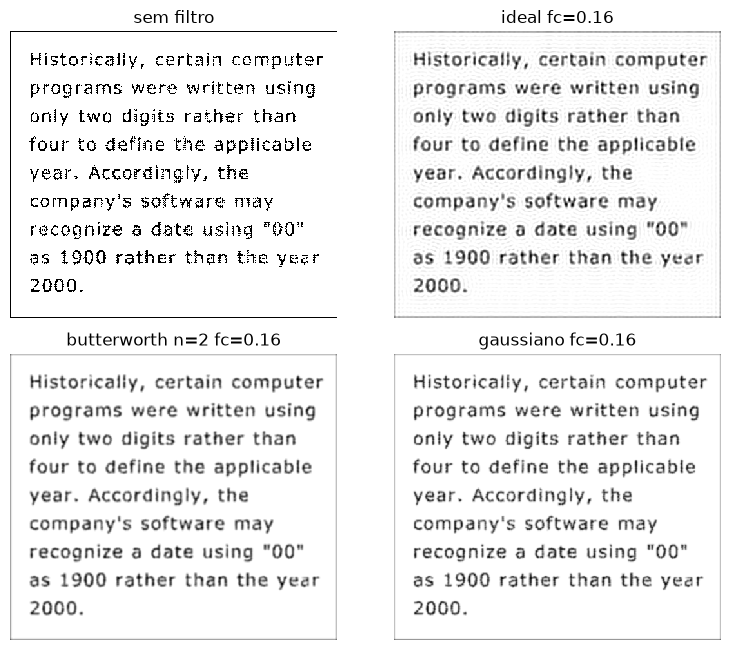

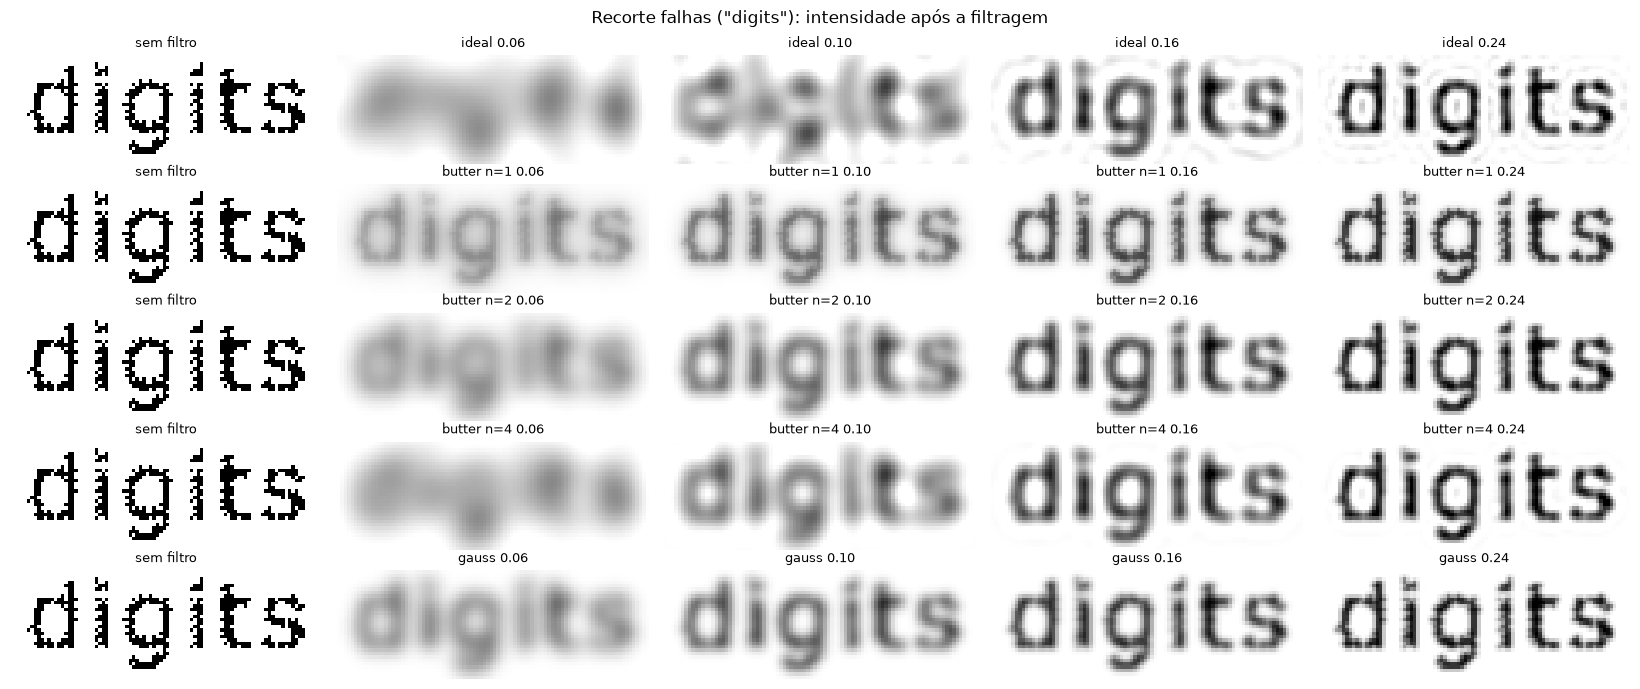

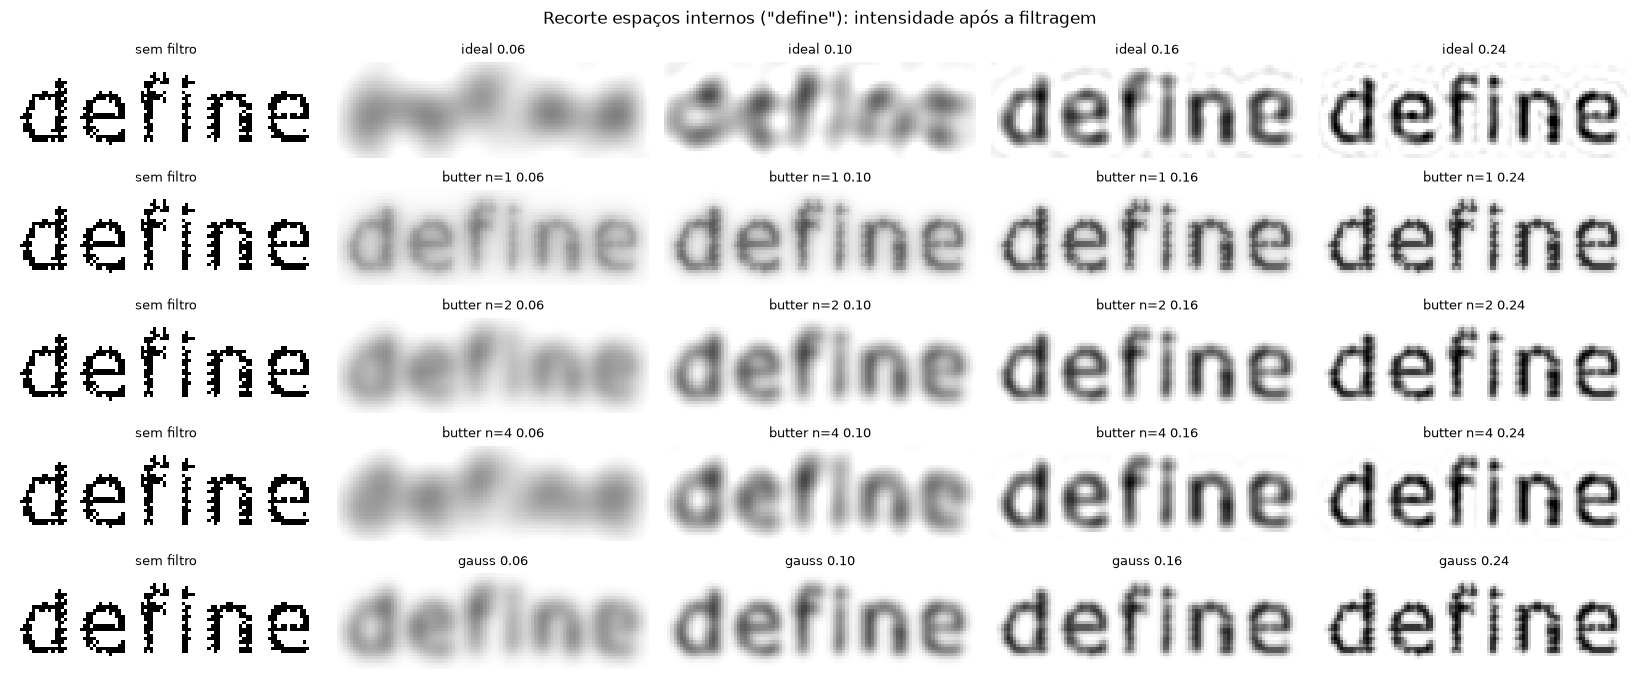

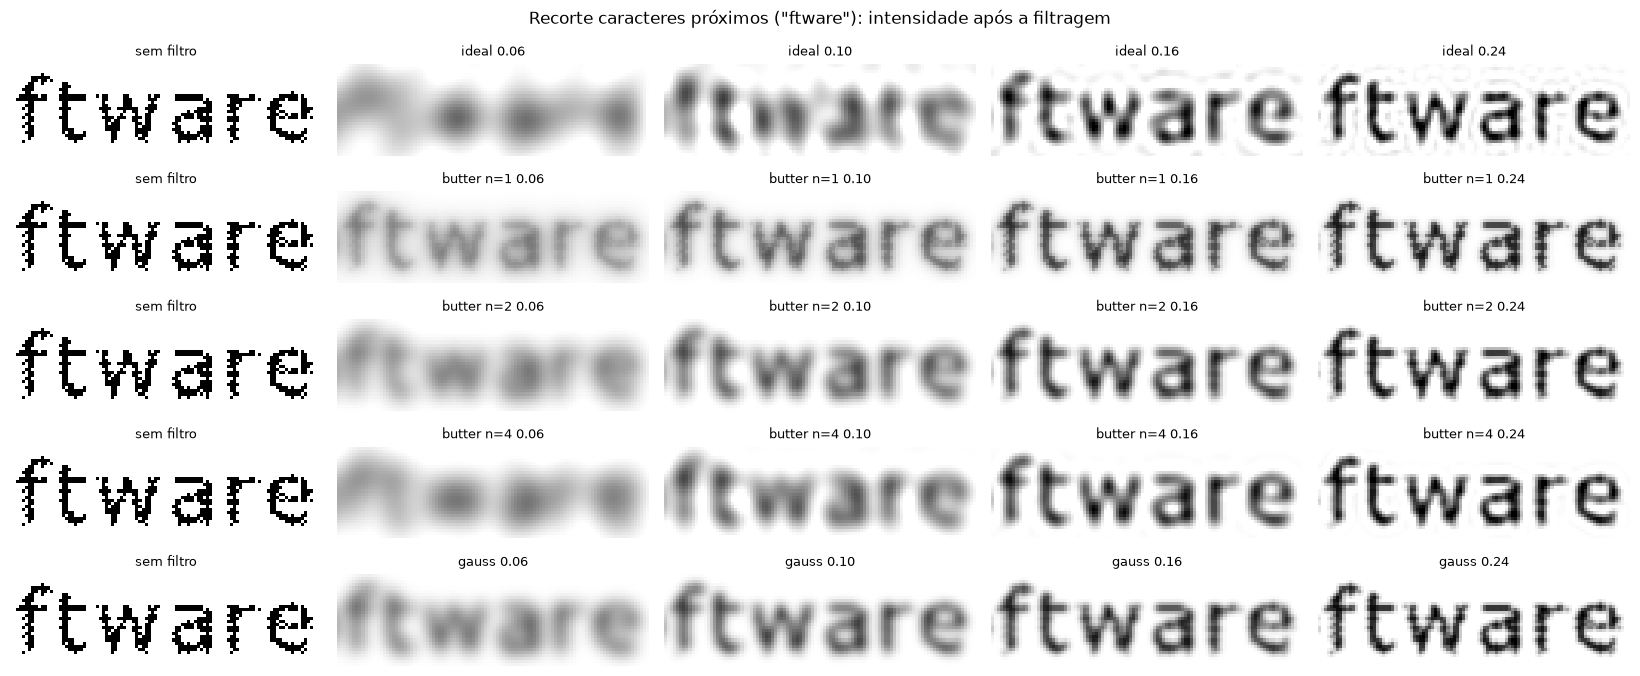

In [8]:
"""IMAGENS FILTRADAS: IMAGEM INTEIRA E RECORTES"""

painel([filtradas[k] for k in ['sem filtro', 'ideal 0.16', 'butter n=2 0.16', 'gauss 0.16']],
       ['sem filtro', 'ideal fc=0.16', 'butterworth n=2 fc=0.16', 'gaussiano fc=0.16'], 2)

def grade_recorte(imagens, caixa, titulo):
    """Linhas = filtro, colunas = sem filtro + cada corte. Mesma escala (0 a 1) em todos os painéis."""
    filtros = ['ideal'] + [f'butter n={n}' for n in ORDENS] + ['gauss']
    fig, axs = plt.subplots(len(filtros), len(CORTES) + 1, figsize=(3.3 * (len(CORTES) + 1), 1.4 * len(filtros)))
    for linha, filtro in zip(axs, filtros):
        for ax, nome in zip(linha, ['sem filtro'] + [f'{filtro} {fc:.2f}' for fc in CORTES]):
            ax.imshow(recortar(imagens[nome], caixa), cmap='gray', vmin=0, vmax=1, interpolation='nearest')
            ax.set_title(nome, fontsize=9); ax.axis('off')
    fig.suptitle(titulo); fig.tight_layout(); plt.show()

for nome, r in RECORTES.items():
    grade_recorte(filtradas, r['caixa'], f'Recorte {nome}: intensidade após a filtragem')

**Resposta**

Etapas de `filtrar_frequencia`:
1. **Preenchimento por reflexão** de meia imagem em cada lado (444x508 -> 888x1016). A DFT supõe que a imagem é periódica, e a reflexão evita uma descontinuidade artificial entre bordas opostas.
2. **`fft2` + `fftshift`:** espectro com a frequência zero no centro (r_c = M//2, c_c = N//2).
3. **`criar_passa_baixa`** (adaptada da `createPB`): calcula D_f em ciclos/pixel, normalizando cada eixo pela dimensão da matriz preenchida, e aplica H_I, H_B ou H_G.
4. **Produto H·F**, `ifftshift`, `ifft2` e parte real.
5. **Recorte** de volta para 444x508 e saturação em [0, 1], porque o ringing do ideal gera valores fora da faixa.

**Parâmetros:** f_c ∈ {0,06; 0,10; 0,16; 0,24} ciclos/pixel para o ideal, o Butterworth (n = 1, 2 e 4) e o gaussiano, num total de 20 configurações mais a entrada sem filtro. A tabela registra o raio equivalente (f_c = 0,10 -> D_0 ≈ 89 nas linhas e ≈ 102 nas colunas) e o σ espacial equivalente do gaussiano, σ = 1/(2π f_c): 2,65; 1,59; 0,99 e 0,66 px.

**Respostas e espectros**
- O perfil radial mostra o ganho diferente em D = f_c: o ideal cai de 1 para 0, o Butterworth vale 0,5 e o gaussiano 0,607.
- O Butterworth n=1 cai devagar e mantém uma cauda longa (≈0,19 em D = 0,5 para f_c = 0,24). O n=4 já é quase um degrau, próximo do ideal.
- O espectro da entrada tem energia até as altas frequências, vinda das bordas abruptas da imagem binária, do serrilhado e das falhas de 1–2 px. As linhas nos eixos vêm das linhas de texto e da moldura.
- O ideal zera tudo fora da elipse; o Butterworth e o gaussiano atenuam de forma gradual.

**Recortes**
- **f_c = 0,24:** as falhas de 1 px ficam cinza-claras e os traços mais contínuos, quase sem perda de detalhe. No gaussiano e no Butterworth n=1, o serrilhado e parte das falhas ainda aparecem.
- **f_c = 0,16:** os traços ficam contínuos em todos os filtros, com desfoque leve. O ideal e o Butterworth n=4 mostram halos (ringing) ao redor das letras.
- **f_c = 0,10:** as falhas desaparecem na intensidade, mas os olhos dos "e" escurecem e as letras próximas ("ft", "tw", "d"–"i") se aproximam.
- **f_c = 0,06:** as palavras viram manchas, e no ideal o ringing deforma as letras.

A aproximação dos traços já aparece na imagem filtrada, mas só vira conexão (ou união indevida) depois da segmentação, analisada no item 3.

### Otsu, Canny e k-means

3. Aplique Otsu, k-means e Canny à imagem sem filtragem e a cada versão filtrada. Apresente os resultados lado a lado, utilizando os mesmos recortes e a mesma escala de exibição. Realize duas comparações:

- Entre métodos: para uma mesma imagem de entrada, compare Otsu, k-means e Canny.
- Antes e depois da filtragem: para um mesmo método, compare a entrada sem filtro com as versões filtradas.

Para Otsu e k-means, analise as máscaras de região: as falhas foram reduzidas? Os traços e espaços internos foram preservados? Houve união entre caracteres? 

Para Canny, analise os mapas de bordas: aparecem contornos adicionais ao redor das falhas? Esses contornos diminuem após a filtragem? As bordas externas dos caracteres continuam bem definidas? 

Canny produz bordas, enquanto Otsu e k-means produzem regiões. Portanto, a ausência de uma borda em uma falha não demonstra, por si só, que a região foi corretamente recuperada. Mantenha fixos os parâmetros do Canny e a configuração do k-means na comparação inicial, registrando-os. O limiar de Otsu será recalculado para cada entrada, pois faz parte do próprio método.

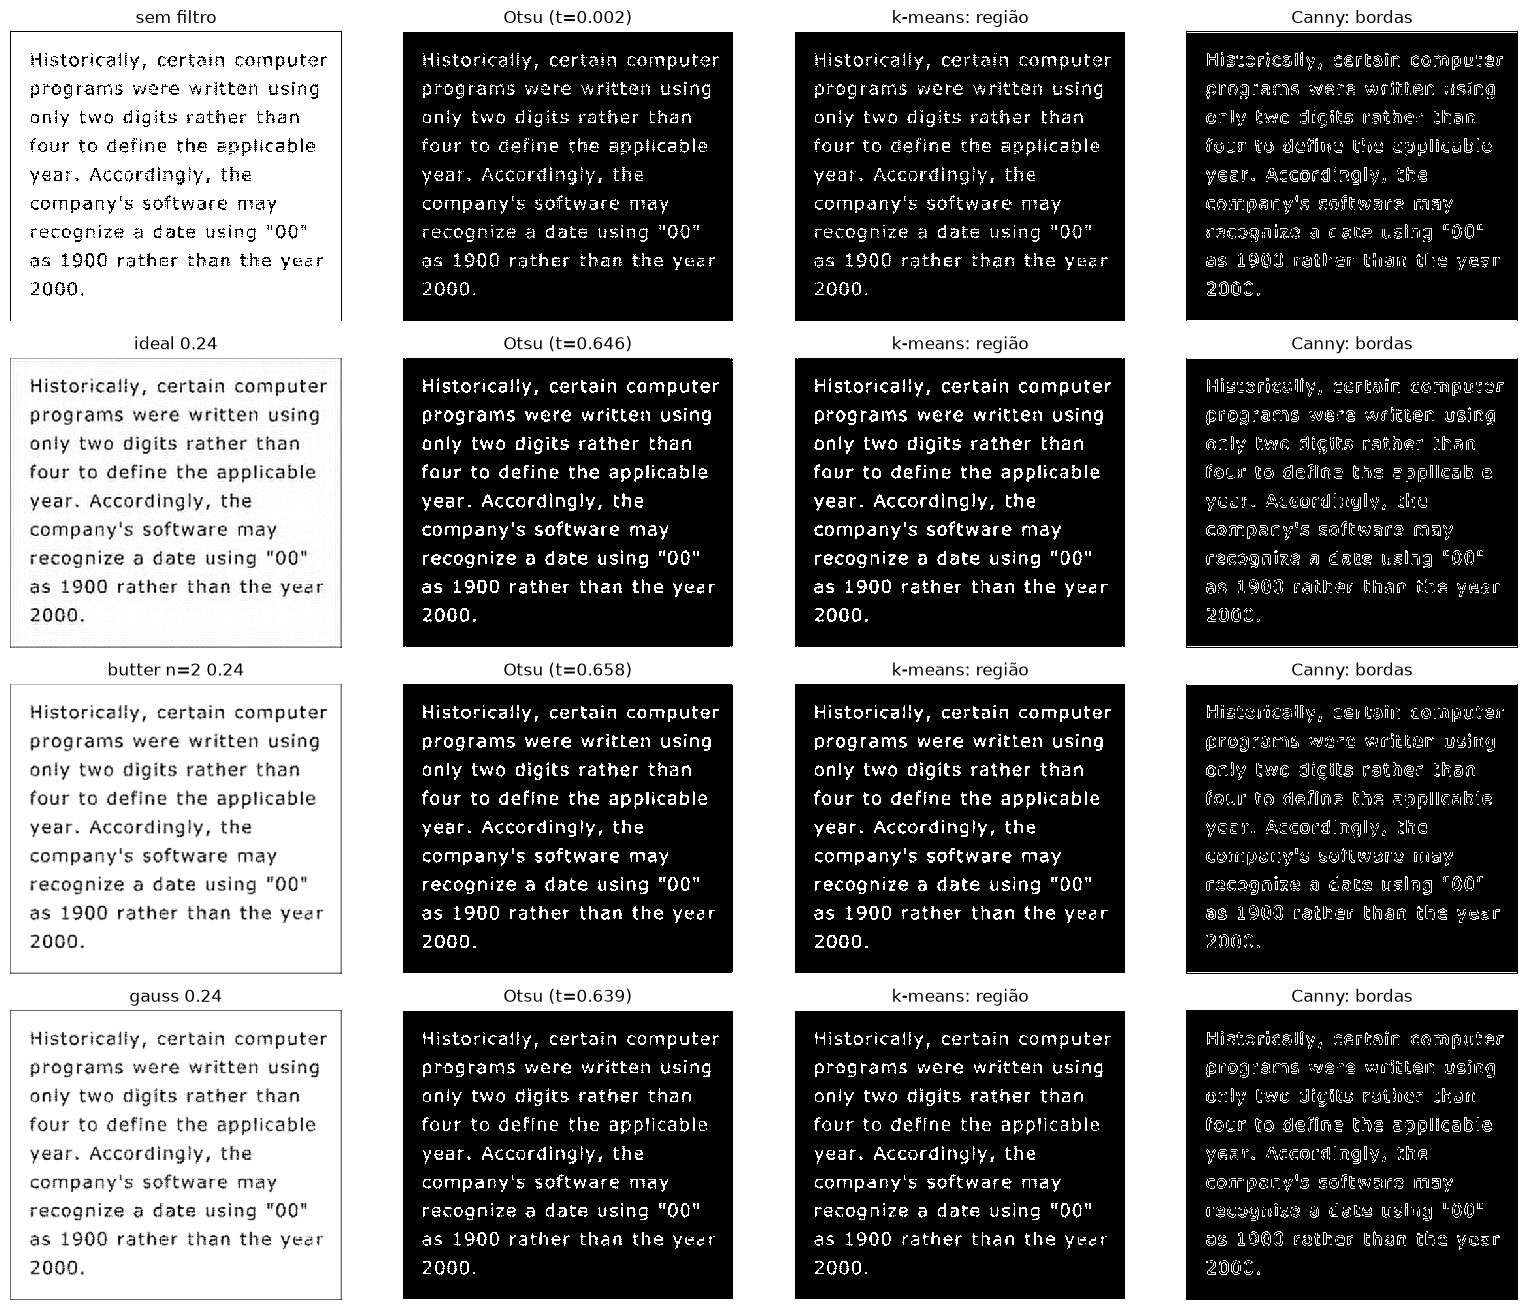

In [9]:
"""SEGMENTAÇÃO: OTSU, K-MEANS E CANNY"""

# Parâmetros fixos em todas as comparações (o limiar de Otsu é recalculado para cada entrada)
KMEANS = dict(n_clusters=2, n_init=10, random_state=42)
CANNY = dict(sigma=1.0, low_threshold=0.1, high_threshold=0.2, mode='nearest')

def segmentar_otsu(imagem):
    """Limiar que maximiza a variância entre as classes do histograma. Texto = abaixo do limiar."""
    t = threshold_otsu(imagem)
    return imagem <= t, t

def segmentar_kmeans(imagem):
    """Agrupa as intensidades dos pixels em 2 grupos; o grupo de centro mais escuro é o texto."""
    km = KMeans(**KMEANS).fit(imagem.reshape(-1, 1))
    texto = np.argmin(km.cluster_centers_.ravel())
    return (km.labels_ == texto).reshape(imagem.shape)

def segmentar(imagem):
    mask_otsu, t = segmentar_otsu(imagem)
    return {'otsu': mask_otsu, 't_otsu': t, 'kmeans': segmentar_kmeans(imagem),
            'canny': canny(imagem, **CANNY)}

seg_real = {nome: segmentar(im) for nome, im in filtradas.items()}

# Imagem inteira: entrada, regiões (Otsu e k-means) e bordas (Canny)
vistas = ['sem filtro', 'ideal 0.24', 'butter n=2 0.24', 'gauss 0.24']
imagens, titulos = [], []
for nome in vistas:
    s = seg_real[nome]
    imagens += [filtradas[nome], s['otsu'], s['kmeans'], s['canny']]
    titulos += [nome, f'Otsu (t={s["t_otsu"]:.3f})', 'k-means: região', 'Canny: bordas']
painel(imagens, titulos, 4)

Recorte falhas ("digits")


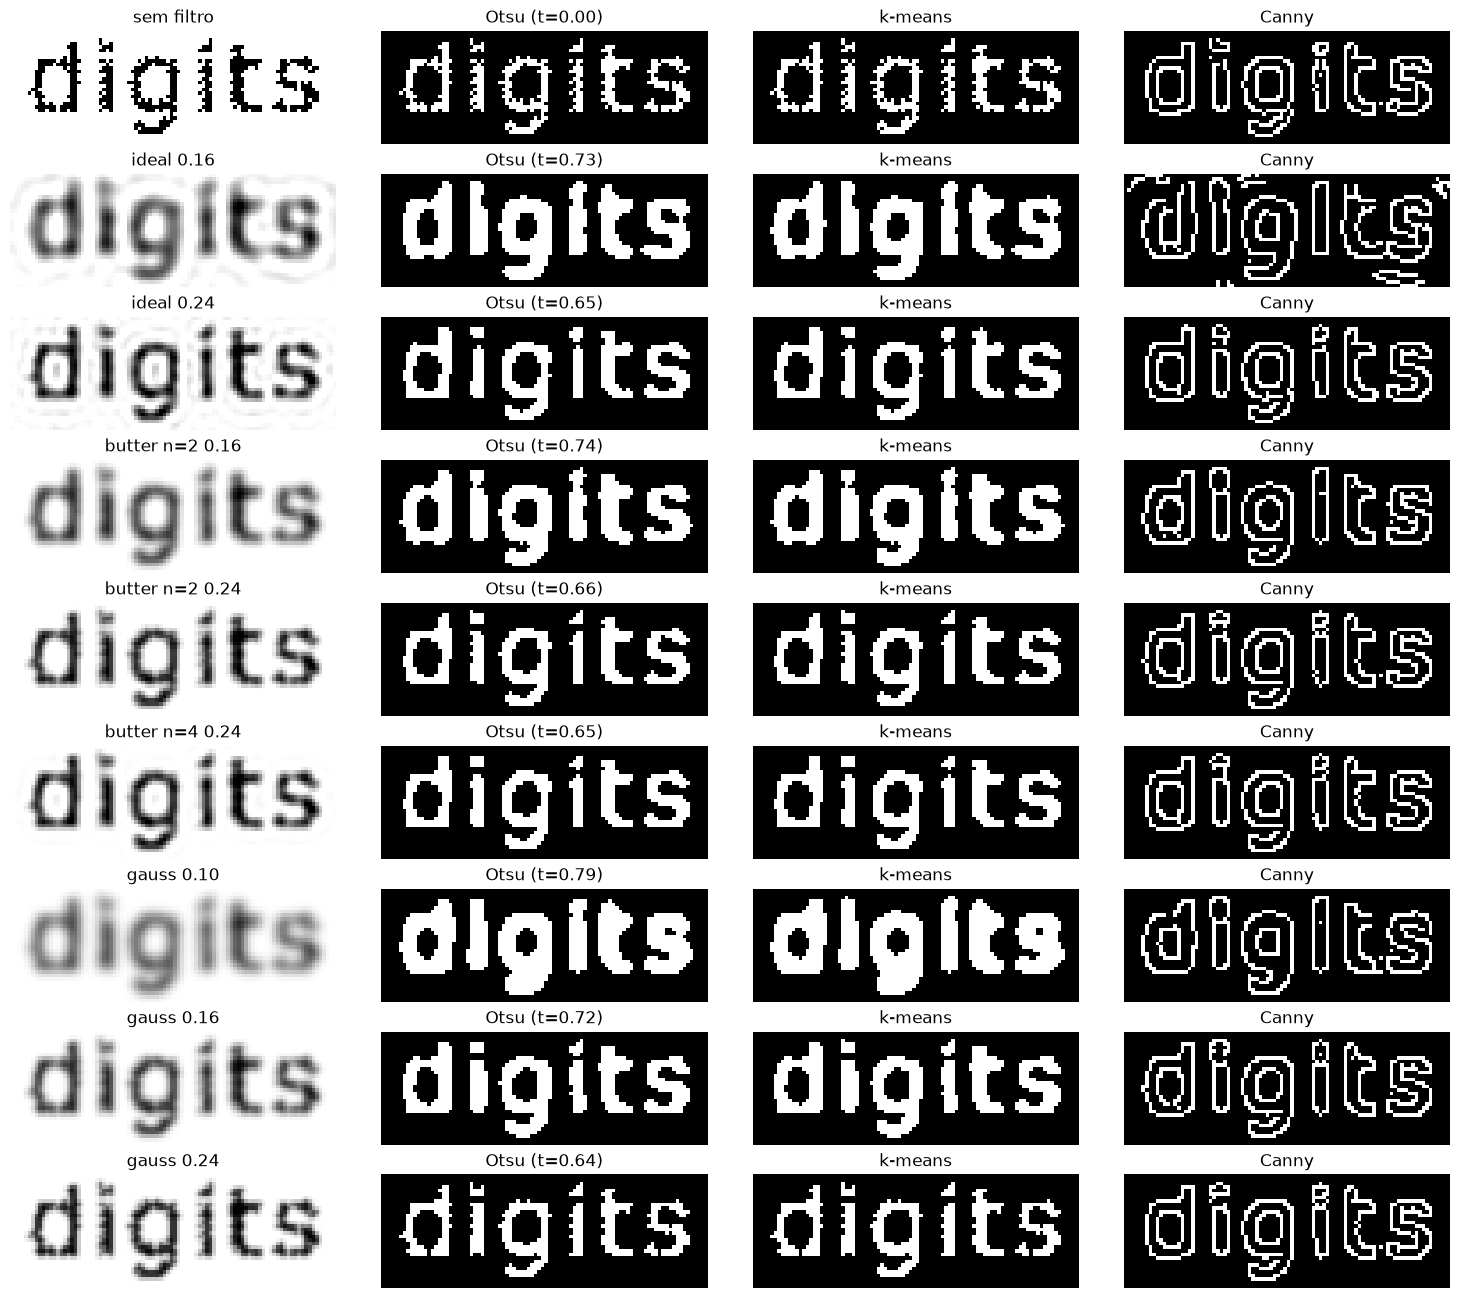

Recorte espaços internos ("define")


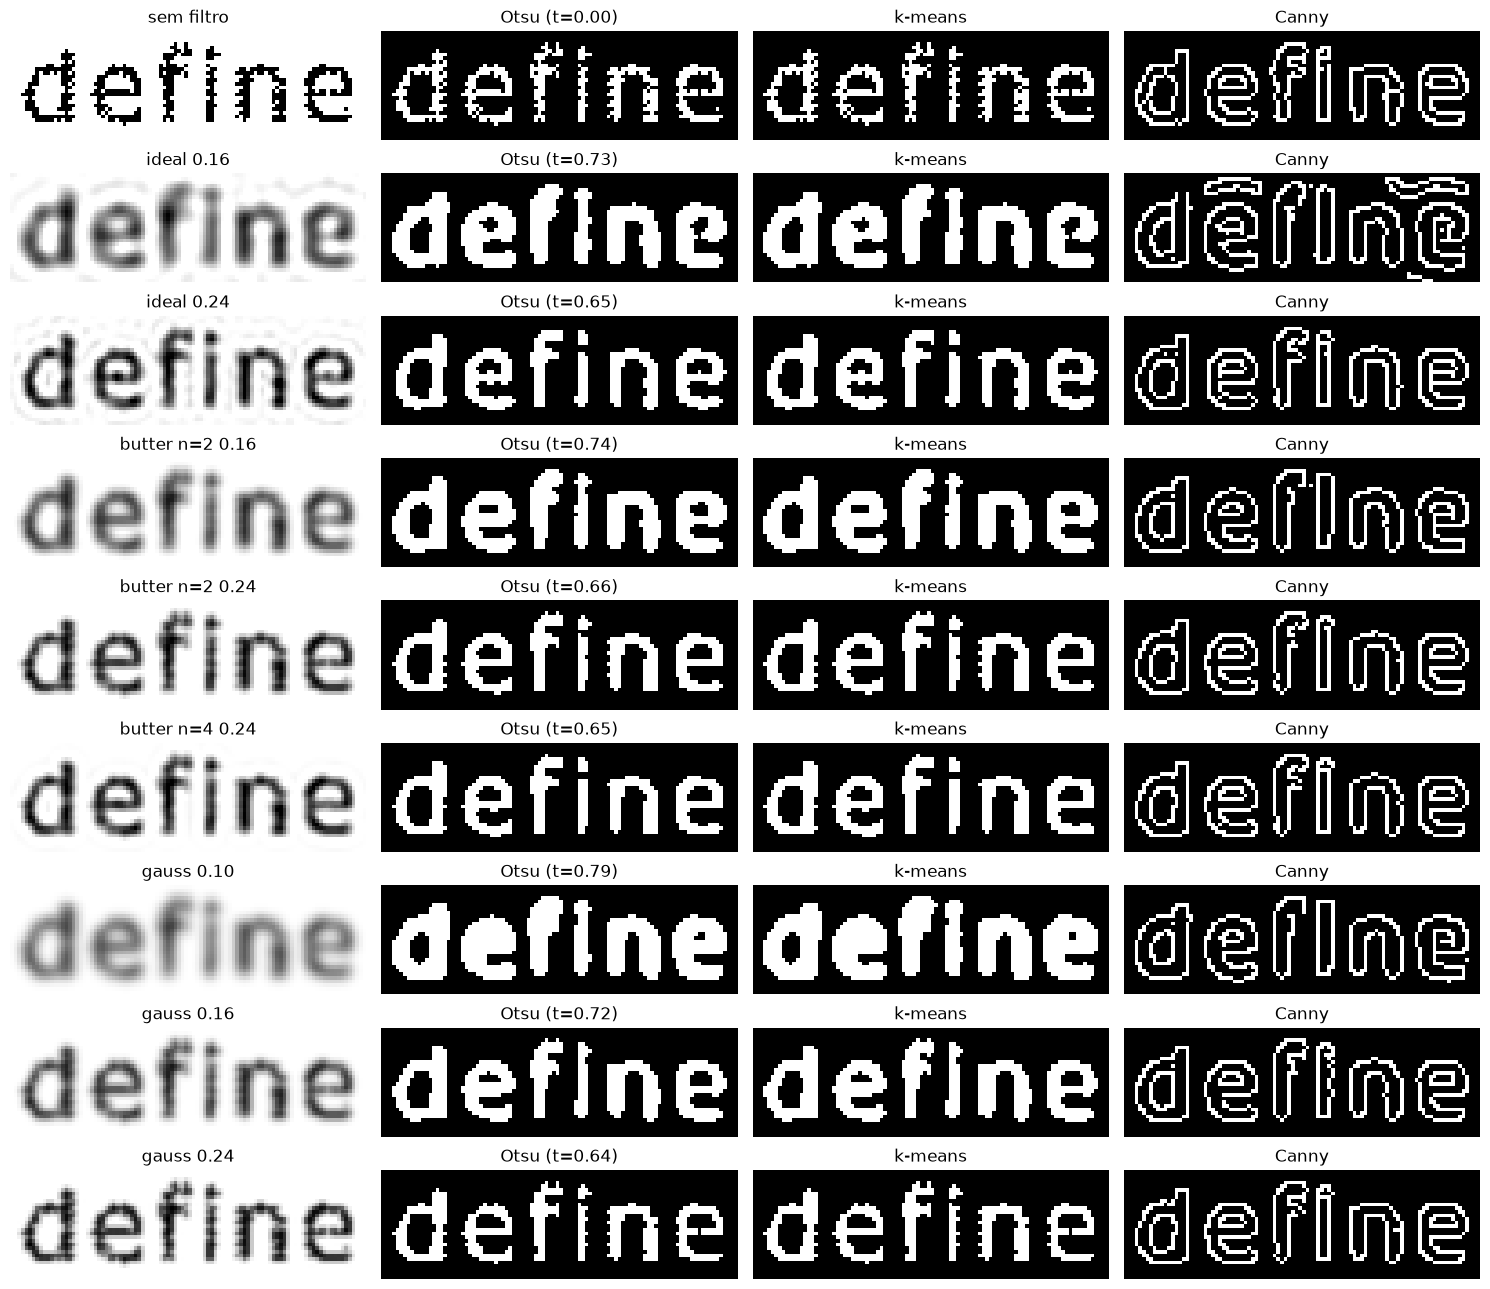

Recorte caracteres próximos ("ftware")


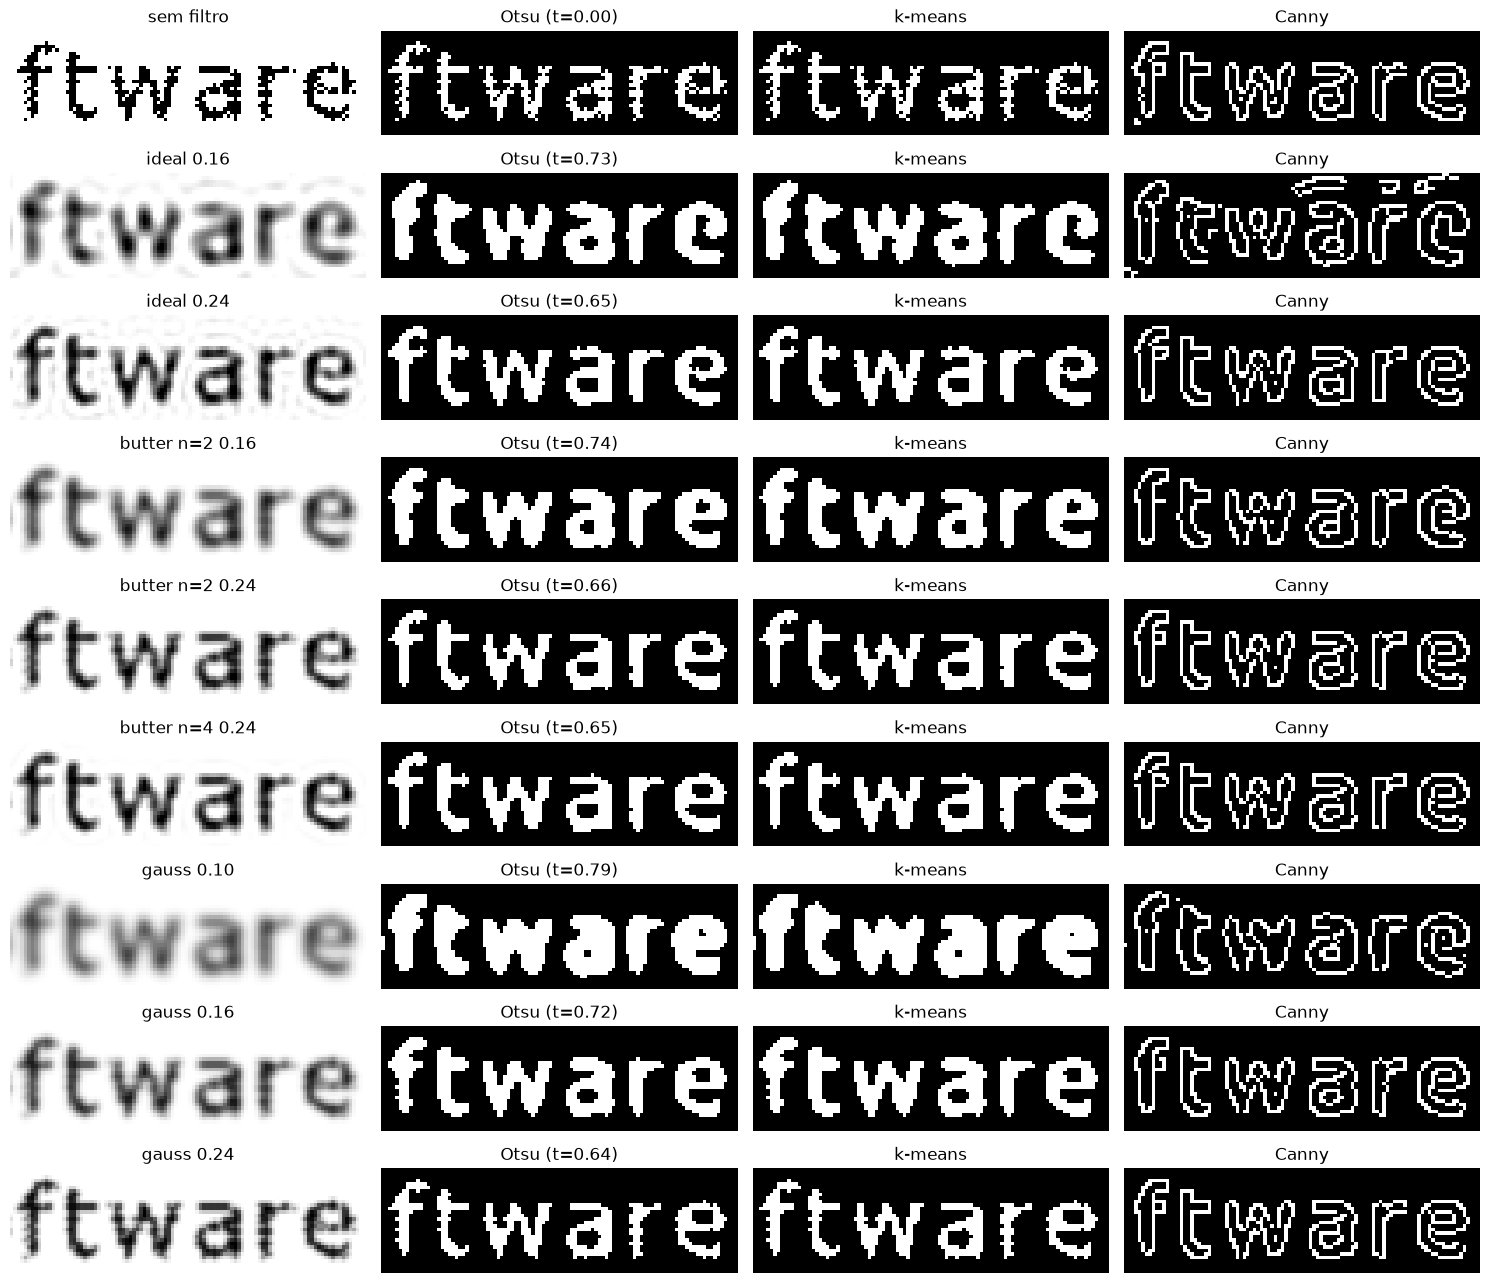

In [10]:
"""RECORTES: COMPARAÇÃO ENTRE MÉTODOS (colunas) E ANTES/DEPOIS DA FILTRAGEM (linhas)"""

SELECAO = ['sem filtro', 'ideal 0.16', 'ideal 0.24', 'butter n=2 0.16', 'butter n=2 0.24',
           'butter n=4 0.24', 'gauss 0.10', 'gauss 0.16', 'gauss 0.24']

for nome_recorte, r in RECORTES.items():
    print(f'Recorte {nome_recorte}')
    imagens, titulos = [], []
    for nome in SELECAO:
        s = seg_real[nome]
        imagens += [recortar(im, r['caixa']) for im in (filtradas[nome], s['otsu'], s['kmeans'], s['canny'])]
        titulos += [nome, f'Otsu (t={s["t_otsu"]:.2f})', 'k-means', 'Canny']
    painel(imagens, titulos, 4, figsize=(15, 1.45 * len(SELECAO)))

In [11]:
"""CONFERÊNCIA DAS MARCAS NOS RECORTES (todas as configurações)"""

def conferir_marcas(mask):
    """Soma os 3 recortes: falhas marcadas que viraram texto e % dos pixels marcados como espaço
    interno ou separação que continuam fundo. Só confere as marcas manuais, não é acurácia."""
    falhas = [mask[y, x] for r in RECORTES.values() for x, y in r['falhas']]
    def fundo_mantido(chave):
        px = np.concatenate([~recortar(mask, caixa).ravel() for r in RECORTES.values() for caixa in r[chave]])
        return 100 * px.mean()
    return {'falhas fechadas': f'{sum(falhas)}/{len(falhas)}',
            'espaços internos %': fundo_mantido('preservar'),
            'separações %': fundo_mantido('separacao')}

linhas = {}
for nome, s in seg_real.items():
    linha = {('Otsu', 'limiar'): s['t_otsu'], ('Otsu', 'texto % da imagem'): 100 * s['otsu'].mean()}
    for metodo, rotulo in (('otsu', 'Otsu'), ('kmeans', 'k-means')):
        for chave, valor in conferir_marcas(s[metodo]).items():
            linha[(rotulo, chave)] = valor
    linha[('k-means', 'px ≠ Otsu')] = np.count_nonzero(s['otsu'] != s['kmeans'])
    linha[('Canny', 'px de borda nos recortes')] = sum(recortar(s['canny'], r['caixa']).sum() for r in RECORTES.values())
    linhas[nome] = linha

tabela_marcas = pd.DataFrame.from_dict(linhas, orient='index')
display(tabela_marcas.round(3))

Otsu                                                       \
                limiar texto % da imagem falhas fechadas espaços internos %   
sem filtro       0.002             7.877            0/18            100.000   
ideal 0.06       0.844            21.691           18/18              0.000   
butter n=1 0.06  0.851            20.543           18/18              0.398   
butter n=2 0.06  0.851            22.315           18/18              0.000   
butter n=4 0.06  0.850            22.500           18/18              0.000   
gauss 0.06       0.846            20.458           18/18              0.000   
ideal 0.10       0.807            18.647           18/18             19.522   
butter n=1 0.10  0.797            14.510           18/18             55.378   
butter n=2 0.10  0.814            18.067           18/18             36.653   
butter n=4 0.10  0.817            19.212           18/18             33.068   
gauss 0.10       0.789            14.929           18/18             58.566   
ideal 0.16       0.729            13.987           18/18             75.697   
butter n=1 0.16  0.729            10.991           18/18             89.641   
butter n=2 0.16  0.736            12.687           18/18             79.283   
butter n=4 0.16  0.744            14.361           18/18             76.096   
gauss 0.16       0.722            11.668           17/18             88.048   
ideal 0.24       0.646            10.174           17/18             96.813   
butter n=1 0.24  0.656             8.759           14/18             99.602   
butter n=2 0.24  0.658             9.806           17/18             98.008   
butter n=4 0.24  0.654            10.076           17/18             97.610   
gauss 0.24       0.639             8.766           14/18            100.000   

                                     k-means                                  \
                separações % falhas fechadas espaços internos % separações %   
sem filtro           100.000            0/18            100.000      100.000   
ideal 0.06            15.044           18/18              0.000       15.044   
butter n=1 0.06       14.159           18/18              0.000       13.274   
butter n=2 0.06       10.619           18/18              0.000        9.735   
butter n=4 0.06       11.504           18/18              0.000       11.504   
gauss 0.06            12.389           18/18              0.000       12.389   
ideal 0.10            36.283           18/18             19.522       34.513   
butter n=1 0.10       90.265           18/18             54.980       90.265   
butter n=2 0.10       69.027           18/18             36.255       68.142   
butter n=4 0.10       61.947           18/18             32.271       61.062   
gauss 0.10            90.265           18/18             56.972       88.496   
ideal 0.16            96.460           18/18             75.697       94.690   
butter n=1 0.16      100.000           18/18             89.243      100.000   
butter n=2 0.16      100.000           18/18             79.283      100.000   
butter n=4 0.16       98.230           18/18             75.697       98.230   
gauss 0.16           100.000           17/18             88.048      100.000   
ideal 0.24            99.115           17/18             96.813       98.230   
butter n=1 0.24      100.000           14/18             99.602      100.000   
butter n=2 0.24      100.000           17/18             98.008      100.000   
butter n=4 0.24      100.000           17/18             97.610      100.000   
gauss 0.24           100.000           14/18            100.000      100.000   

                                             Canny  
                px ≠ Otsu px de borda nos recortes  
sem filtro              0                     1414  
ideal 0.06            159                      765  
butter n=1 0.06       414                     1303  
butter n=2 0.06       362                     1034  
butter n=4 0.06       312                

**Resposta**

**Parâmetros fixos**
- **k-means:** k = 2 sobre as intensidades, `n_init=10`, `random_state=42`; o texto é o grupo de centro mais escuro.
- **Canny:** σ = 1,0, limiares de histerese 0,1 e 0,2 e `mode='nearest'`, que evita bordas falsas no contorno da imagem.
- **Otsu:** o limiar é recalculado para cada entrada.

**Entre métodos (mesma entrada)**
- **Otsu e k-means sem filtro:** como a entrada é binária, os dois (t = 0,002) devolvem exatamente a própria imagem (0 px de diferença). Nenhuma falha é recuperada (0/18), e todos os espaços internos e separações são mantidos.
- **Canny sem filtro:** já passa por cima de parte das falhas, porque o próprio Canny suaviza com uma gaussiana (σ = 1). Mesmo assim, os contornos ficam serrilhados e há pequenos laços em volta das falhas, como no "d" e no "s" de "digits" (1414 px de borda nos recortes).
- **Otsu x k-means:** ficam praticamente iguais em todas as entradas, com no máximo 427 px diferentes em 225 552 (exceto `gauss 0.10`, com 2824). Em 1D, os dois minimizam a variância dentro das classes: o Otsu testa todos os limiares do histograma, e o k-means converge para um limiar no ponto médio entre os dois centros.

**Antes e depois da filtragem (mesmo método)**
- **Efeito dominante nas regiões: o limiar do Otsu.** Ele sobe de 0,002 para 0,64–0,85, porque a suavização espalha o texto em tons intermediários e o centro da classe "texto" clareia. Todo o halo abaixo do limiar vira texto, e a área de texto cresce de 7,9% para 8,8–22,5% da imagem (engrossamento).
- **f_c = 0,24:** o ideal e o Butterworth n=2 ou n=4 fecham 17 das 18 falhas marcadas e mantêm 97–98% dos espaços internos e 99–100% das separações. O gaussiano e o Butterworth n=1 mantêm tudo, mas fecham só 14/18.
- **f_c = 0,16:** fecha 17–18/18, mas os olhos dos "e" encolhem (76–90% mantidos) e o traço fica visivelmente mais grosso.
- **f_c ≤ 0,10:** os espaços internos somem (0–59% mantidos) e os caracteres se unem (11–90% das separações mantidas), como em "ft" e "tw".
- **Canny:**
  - Com Butterworth n=2 e gaussiano, os laços em volta das falhas somem e o contorno externo fica liso (1364–1395 px de borda nos recortes).
  - O ideal cria contornos extras pelo ringing (1647 px em f_c = 0,16).
  - Em cortes baixos, os contornos de letras vizinhas se fundem e as bordas enfraquecem.
- **Borda ≠ região:** a ausência de borda numa falha não prova que a região foi recuperada. Em `gauss 0.24`, o contorno do Canny já é quase contínuo nos recortes, mas a máscara do Otsu ainda deixa 4 das 18 falhas abertas.

### Experimento controlado com referência conhecida

Para avaliar recuperação, criamos caracteres íntegros e apagamos pequenas faixas de 1 e 2 pixels. Acrescentamos ruído fraco com semente fixa. A degradação é uma edição direta de pixels. Use o PSNR e SSIM para medir fidelidade e [IoU e Dice](https://medium.com/mastering-data-science/understanding-evaluation-metrics-in-medical-image-segmentation-d289a373a3f) comparam regiões de texto. Para avaliar o resultado do Canny, podemos usar a métrica [F1](https://www.newroom.io/blog/top-8-metrics-to-evaluate-edge-detection-performance) de bordas, onde vocês podem utilizar a tolerância de 1,5 pixel, obtida por distância euclidiana a uma borda de referência calculada por diferenças entre vizinhos, sendo que essa tolerância permite pequenos deslocamentos. O F1 mede presença próxima, sem correspondência um a um, e deve ser acompanhado das imagens e é a única métrica recomendada para vocês compararem Otsu, k-means e Canny, sendo que IoU e Dice são boas para Otsu e k-means devido ao tipo de saída de ambos.

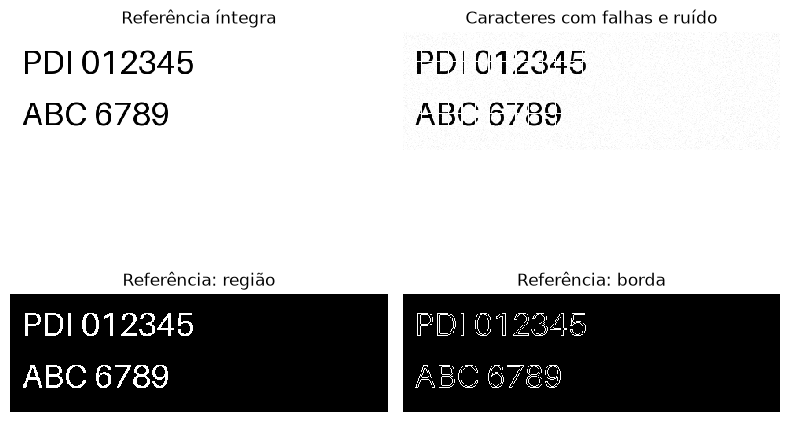

In [12]:
SEMENTE = 42

def exemplo_controlado():
    tela = Image.new('L', (480, 150), 255)
    # Fontes locais opcionais; o fallback do Pillow mantém execução sem download.
    fonte = None
    for nome in ['DejaVuSans-Bold.ttf', 'Arial.ttf']:
        try:
            fonte = ImageFont.truetype(nome, 42); break
        except OSError: pass
    if fonte is None: fonte = ImageFont.load_default(size=42)
    desenho = ImageDraw.Draw(tela)
    desenho.text((15, 12), 'PDI 012345', fill=0, font=fonte)
    desenho.text((15, 78), 'ABC 6789', fill=0, font=fonte)
    limpa = np.asarray(tela, dtype=float) / 255
    falha = limpa.copy()
    for x in range(24, 455, 17): falha[:, x:x+1+(x%2)] = 1
    falha[37:38, :] = 1; falha[103:105, :] = 1
    rng = np.random.default_rng(SEMENTE)
    degradada = np.clip(falha + rng.normal(0, 0.025, falha.shape), 0, 1)
    return limpa, degradada

def borda_por_diferencas(mask):
    # Borda interna: marca pixel de texto com vizinho ortogonal diferente.
    p = np.pad(mask, 1, constant_values=False)
    centro = p[1:-1, 1:-1]
    return centro & ((centro != p[:-2,1:-1]) | (centro != p[2:,1:-1]) |
                     (centro != p[1:-1,:-2]) | (centro != p[1:-1,2:]))

def metricas_regiao(pred, ref):
    inter = np.count_nonzero(pred & ref)
    uniao = np.count_nonzero(pred | ref)
    soma = pred.sum() + ref.sum()
    return {'IoU': inter/uniao if uniao else 1.0,
            'Dice': 2*inter/soma if soma else 1.0}

def f1_bordas(pred, ref, tolerancia=1.5):
    if not pred.any() or not ref.any():
        return float(np.array_equal(pred, ref))
    precisao = np.mean(distance_transform_edt(~ref)[pred] <= tolerancia)
    revocacao = np.mean(distance_transform_edt(~pred)[ref] <= tolerancia)
    return 2*precisao*revocacao/(precisao+revocacao) if precisao+revocacao else 0.0

limpa, degradada = exemplo_controlado()
ref_texto = limpa < 0.5
ref_borda = borda_por_diferencas(ref_texto)
painel([limpa, degradada, ref_texto, ref_borda],
       ['Referência íntegra', 'Caracteres com falhas e ruído', 'Referência: região', 'Referência: borda'], 2)

### Varredura de parâmetros e comparação com a entrada sem filtro

4. No experimento sintético, utilize a imagem íntegra e sua máscara de texto como referências. Registre também os pixels de texto apagados para produzir as falhas. Avalie:

- PSNR e SSIM: fidelidade das imagens de intensidade em relação à imagem íntegra.
- IoU e Dice: qualidade das máscaras de região produzidas por Otsu e k-means.
- F1 de bordas: qualidade dos contornos. Para comparar os três métodos, extraia as bordas das máscaras de Otsu e k-means e compare-as, junto com Canny, com a mesma borda de referência e a mesma tolerância.

Para avaliar diretamente a redução das falhas, calcule, nas máscaras de Otsu e k-means, a porcentagem dos pixels apagados que voltaram a ser classificados como texto. Compare esse valor antes e depois da filtragem.

Essa porcentagem não deve ser analisada isoladamente: uma máscara excessivamente engrossada pode recuperar os pixels apagados e também classificar o fundo como texto. Apresente falsos positivos e verifique a preservação dos espaços internos e da separação entre caracteres. Na imagem real, sem referência íntegra, apresente uma avaliação visual dos recortes marcados, sem atribuir métricas de acurácia a partir de uma referência desconhecida.

**Dica**: No texto acima, há uma explicação das métricas IoU, Dice e F1.

In [13]:
"""EXPERIMENTO SINTÉTICO: VARREDURA DE PARÂMETROS"""

# Pixels de texto apagados: mesmas faixas usadas em exemplo_controlado()
faixas = np.zeros(limpa.shape, dtype=bool)
for x in range(24, 455, 17): faixas[:, x:x+1+(x%2)] = True
faixas[37:38, :] = True; faixas[103:105, :] = True
apagados = ref_texto & faixas

# Caracteres com vizinhança-8 (o fundo usa a vizinhança-4 padrão do label)
VIZ8 = np.ones((3, 3), dtype=int)
rot_ref, n_caracteres = label(ref_texto, structure=VIZ8)

def mapa_buracos(mask):
    """Fundo que não toca a borda da imagem = espaços internos fechados (ex.: '0', 'A', 'B')."""
    rot, n = label(~mask)
    borda = np.unique(np.concatenate([rot[0], rot[-1], rot[:, 0], rot[:, -1]]))
    borda = borda[borda > 0]
    return (rot > 0) & ~np.isin(rot, borda), n - len(borda)

def unioes_e_fragmentos(mask):
    """Uniões: caracteres de referência a mais dentro de uma mesma componente segmentada.
    Fragmentos: componentes a mais dentro de um mesmo caractere (traço ainda interrompido)."""
    rot, _ = label(mask, structure=VIZ8)
    sobrepoe = mask & (rot_ref > 0)
    pares = np.unique(np.stack([rot[sobrepoe], rot_ref[sobrepoe]]), axis=1)
    _, refs_por_componente = np.unique(pares[0], return_counts=True)
    _, componentes_por_ref = np.unique(pares[1], return_counts=True)
    return int(np.sum(refs_por_componente - 1)), int(np.sum(componentes_por_ref - 1))

buracos_ref, n_buracos_ref = mapa_buracos(ref_texto)
print(f'Referência: {ref_texto.sum()} px de texto | {apagados.sum()} px apagados ({apagados.sum() / ref_texto.sum():.1%}) | '
      f'{n_caracteres} caracteres | {n_buracos_ref} espaços internos ({buracos_ref.sum()} px)')

def avaliar_regiao(mask):
    unioes, fragmentos = unioes_e_fragmentos(mask)
    return {**metricas_regiao(mask, ref_texto),
            'recuperação %': 100 * mask[apagados].mean(),                              # apagados que voltaram a ser texto
            'FP %': 100 * np.count_nonzero(mask & ~ref_texto) / ref_texto.sum(),      # fundo virando texto (relativo à área de texto)
            'espaços internos %': 100 * np.mean(~mask[buracos_ref]),                  # área interna das letras que segue fundo
            f'nº espaços (ref={n_buracos_ref})': mapa_buracos(mask)[1],
            'uniões': unioes, 'fragmentos': fragmentos}

filtradas_sint = aplicar_configs(degradada)
seg_sint = {nome: segmentar(im) for nome, im in filtradas_sint.items()}

fidelidade, regioes = {}, {'otsu': {}, 'kmeans': {}}
for nome, im in filtradas_sint.items():
    s = seg_sint[nome]
    fidelidade[nome] = {'limiar Otsu': s['t_otsu'],
                        'PSNR (dB)': peak_signal_noise_ratio(limpa, im, data_range=1),
                        'SSIM': structural_similarity(limpa, im, data_range=1),
                        'F1 Otsu': f1_bordas(borda_por_diferencas(s['otsu']), ref_borda),
                        'F1 k-means': f1_bordas(borda_por_diferencas(s['kmeans']), ref_borda),
                        'F1 Canny': f1_bordas(s['canny'], ref_borda),
                        'Canny px / px da borda ref': s['canny'].sum() / ref_borda.sum()}
    for metodo in regioes:
        regioes[metodo][nome] = avaliar_regiao(s[metodo])

fidelidade = pd.DataFrame.from_dict(fidelidade, orient='index')
regioes = {metodo: pd.DataFrame.from_dict(linhas, orient='index') for metodo, linhas in regioes.items()}

print('Fidelidade da intensidade (em relação à imagem íntegra) e F1 de bordas (tolerância 1,5 px)')
display(fidelidade.round(3))
for metodo, rotulo in (('otsu', 'Otsu'), ('kmeans', 'k-means')):
    print(f'Máscaras de região - {rotulo}')
    display(regioes[metodo].round(3))

Referência: 3709 px de texto | 541 px apagados (14.6%) | 16 caracteres | 11 espaços internos (1571 px)
Fidelidade da intensidade (em relação à imagem íntegra) e F1 de bordas (tolerância 1,5 px)


,limiar Otsu,PSNR (dB),SSIM,F1 Otsu,F1 k-means,F1 Canny,Canny px / px da borda ref
sem filtro,0.525,21.441,0.821,0.991,0.992,0.999,1.196
ideal 0.06,0.831,15.419,0.743,0.237,0.231,0.310,0.905
butter n=1 0.06,0.828,16.859,0.852,0.386,0.386,0.942,1.145
butter n=2 0.06,0.836,16.159,0.815,0.171,0.168,0.459,1.030
butter n=4 0.06,0.839,15.724,0.793,0.158,0.158,0.242,0.912
gauss 0.06,0.821,16.744,0.844,0.291,0.290,0.579,1.095
ideal 0.10,0.756,17.652,0.795,0.604,0.603,0.537,1.372
butter n=1 0.10,0.762,18.520,0.896,0.951,0.950,0.974,1.163
butter n=2 0.10,0.764,18.173,0.882,0.788,0.773,0.812,1.129
butter n=4 0.10,0.767,17.887,0.866,0.602,0.602,0.612,1.125


Máscaras de região - Otsu


,IoU,Dice,recuperação %,FP %,espaços internos %,nº espaços (ref=11),uniões,fragmentos
sem filtro,0.844,0.915,0.000,1.105,99.491,1,0,57
ideal 0.06,0.354,0.523,73.937,160.825,19.987,6,10,1
butter n=1 0.06,0.471,0.641,93.346,109.733,36.474,10,8,0
butter n=2 0.06,0.397,0.568,95.009,148.207,22.151,8,9,0
butter n=4 0.06,0.367,0.536,91.128,165.624,17.441,7,10,0
gauss 0.06,0.462,0.632,94.824,113.777,39.911,10,8,0
ideal 0.10,0.533,0.695,88.355,79.914,54.360,13,4,2
butter n=1 0.10,0.653,0.790,76.340,47.425,71.165,12,1,4
butter n=2 0.10,0.585,0.738,86.322,65.867,63.590,11,3,1
butter n=4 0.10,0.540,0.702,90.573,80.507,56.779,13,3,1


Máscaras de região - k-means


,IoU,Dice,recuperação %,FP %,espaços internos %,nº espaços (ref=11),uniões,fragmentos
sem filtro,0.842,0.914,0.000,1.294,99.363,1,0,57
ideal 0.06,0.354,0.523,75.231,161.823,19.796,6,10,1
butter n=1 0.06,0.471,0.641,93.346,109.733,36.474,10,8,0
butter n=2 0.06,0.395,0.567,95.194,149.609,21.642,8,9,0
butter n=4 0.06,0.366,0.536,91.497,165.921,17.441,7,10,0
gauss 0.06,0.461,0.632,95.009,113.939,39.847,10,8,0
ideal 0.10,0.533,0.695,88.540,79.941,54.297,13,4,2
butter n=1 0.10,0.652,0.789,76.525,47.641,71.101,12,1,4
butter n=2 0.10,0.581,0.735,86.876,67.269,63.081,11,3,1
butter n=4 0.10,0.540,0.702,90.573,80.507,56.779,13,3,1


Otsu: sem filtro x 3 primeiras do critério


,IoU,Dice,recuperação %,FP %,espaços internos %,nº espaços (ref=11),uniões,fragmentos
sem filtro,0.844,0.915,0.000,1.105,99.491,1,0,57
butter n=4 0.16,0.708,0.829,69.501,32.354,82.750,7,0,3
ideal 0.16,0.705,0.827,70.610,32.300,82.559,7,0,3
gauss 0.16,0.771,0.871,25.878,14.074,91.343,4,0,20


k-means: sem filtro x 3 primeiras do critério


,IoU,Dice,recuperação %,FP %,espaços internos %,nº espaços (ref=11),uniões,fragmentos
sem filtro,0.842,0.914,0.000,1.294,99.363,1,0,57
ideal 0.16,0.706,0.827,71.534,32.489,82.559,7,0,3
butter n=4 0.16,0.705,0.827,69.686,33.028,82.368,7,0,3
gauss 0.16,0.771,0.871,26.063,14.209,91.216,4,0,20


Maior F1 do Canny: sem filtro | maior PSNR: butter n=4 0.24 | maior SSIM: butter n=2 0.24


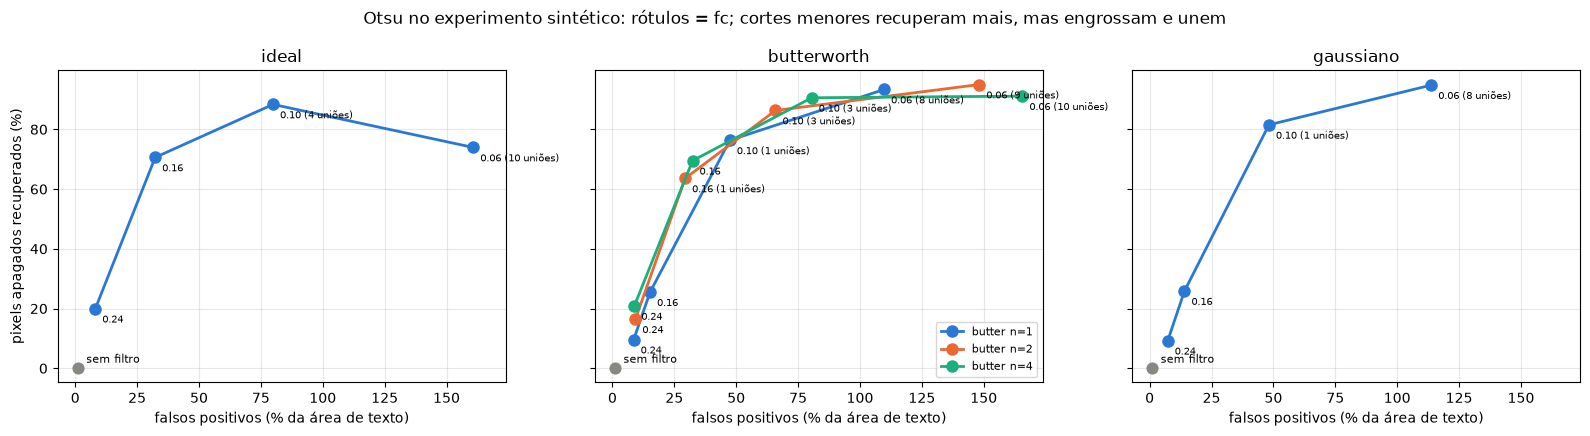

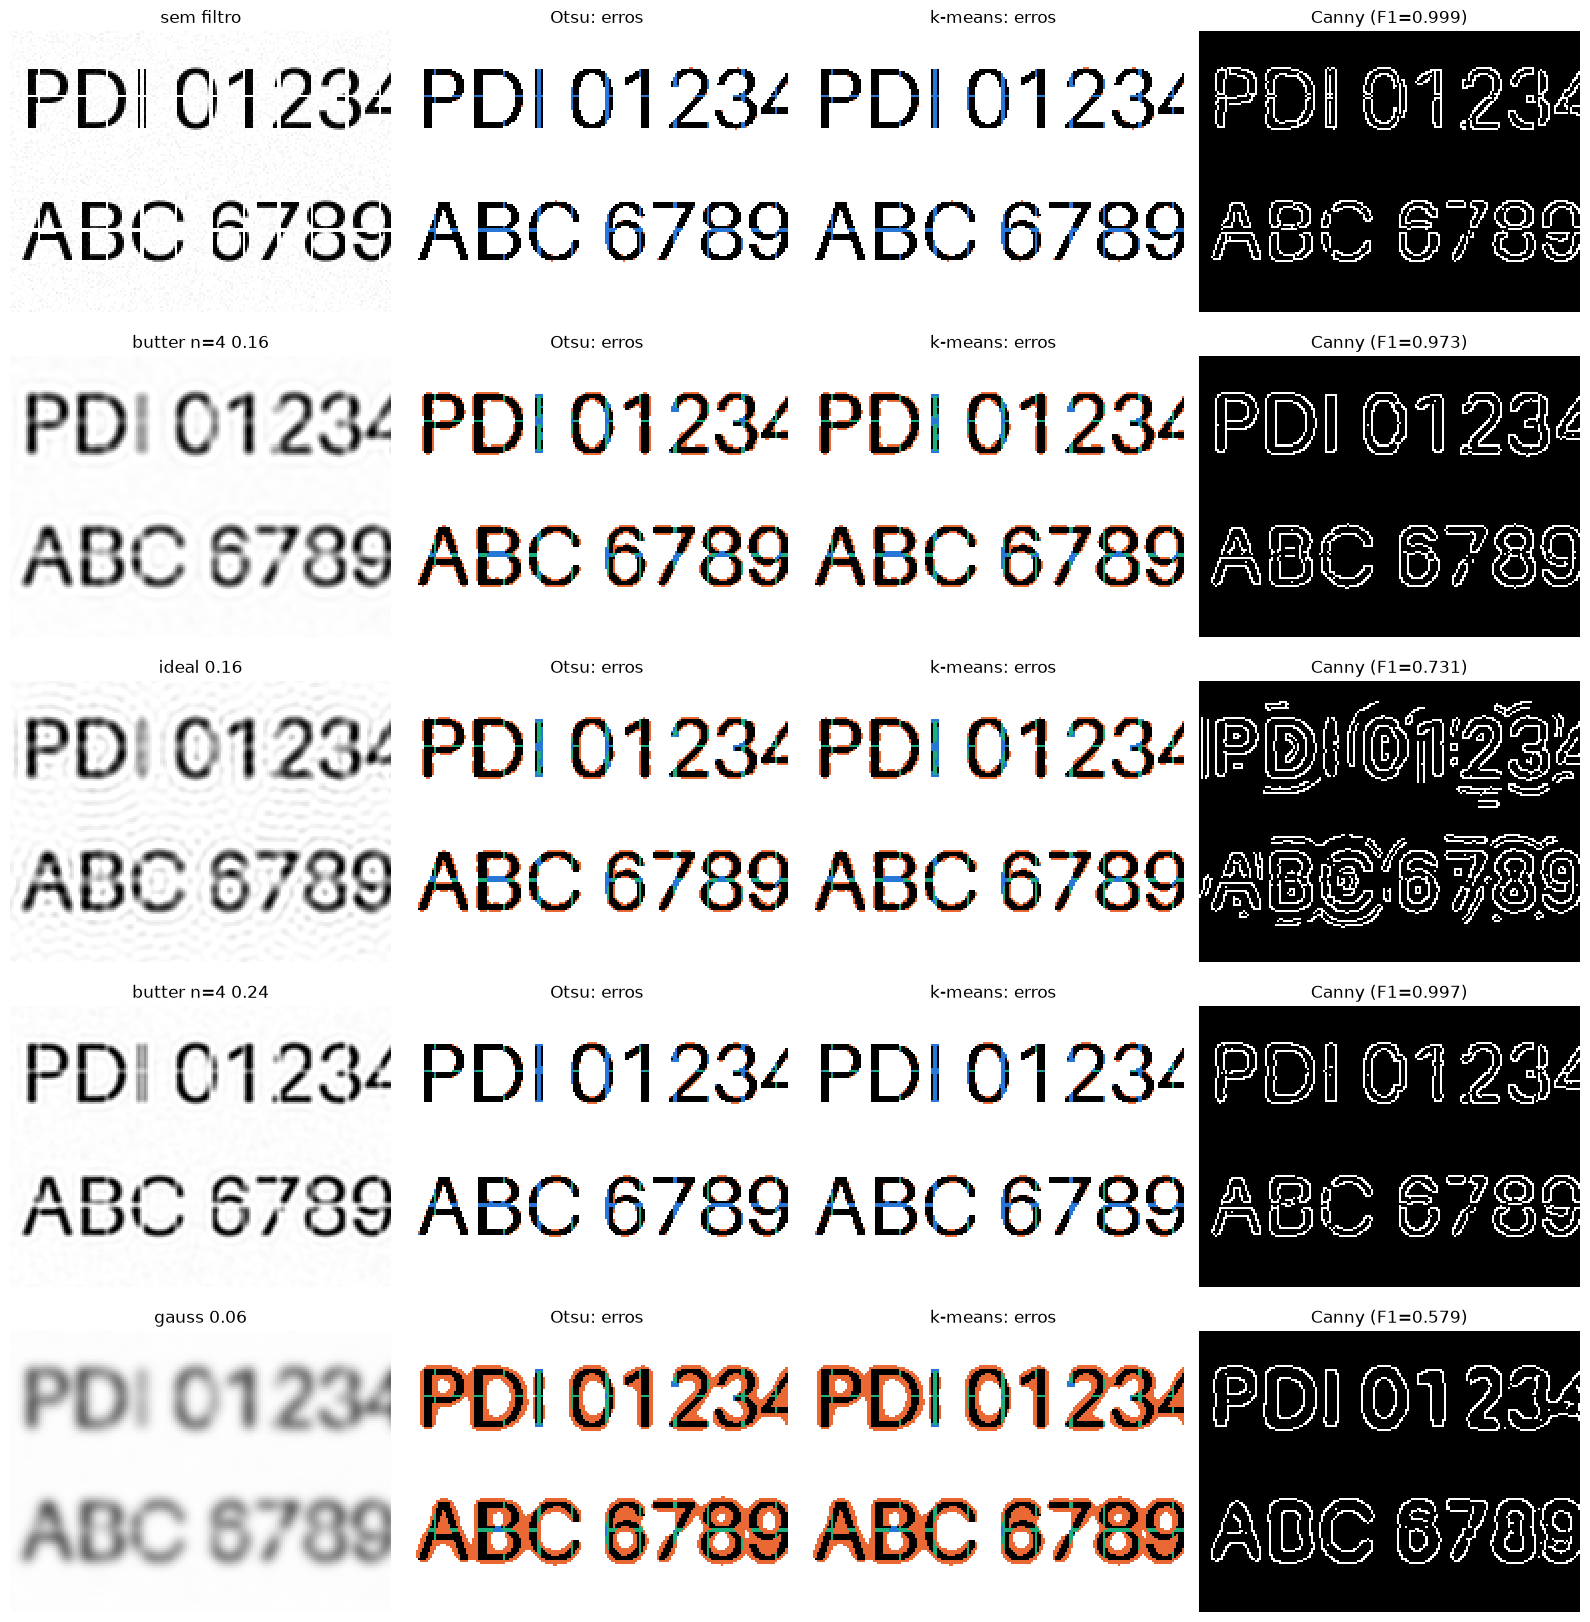

Mapa de erros: preto = texto correto | azul = texto perdido | laranja = falso positivo | verde-água = apagado recuperado


In [14]:
"""MELHOR EQUILÍBRIO POR SEGMENTADOR"""

def ranking_equilibrio(tabela):
    """Critério: nenhuma união de caracteres -> menos fragmentos (falhas restantes) -> maior IoU (menos engrossamento)."""
    candidatas = tabela[tabela['uniões'] == 0]
    return candidatas.sort_values(['fragmentos', 'IoU'], ascending=[True, False])

melhores = {}
for metodo, rotulo in (('otsu', 'Otsu'), ('kmeans', 'k-means')):
    ranking = ranking_equilibrio(regioes[metodo])
    melhores[metodo] = ranking.index[0]
    print(f'{rotulo}: sem filtro x 3 primeiras do critério')
    display(regioes[metodo].loc[['sem filtro'] + list(ranking.index[:3])].round(3))
melhores['canny'] = fidelidade['F1 Canny'].idxmax()
print('Maior F1 do Canny:', melhores['canny'], '| maior PSNR:', fidelidade['PSNR (dB)'].idxmax(),
      '| maior SSIM:', fidelidade['SSIM'].idxmax())

# Compromisso recuperação x falsos positivos (Otsu), uma faceta por família de filtro
familias = [('ideal', ['ideal']), ('butterworth', [f'butter n={n}' for n in ORDENS]), ('gaussiano', ['gauss'])]
cores = ['#2a78d6', '#eb6834', '#1baf7a']
base = regioes['otsu'].loc['sem filtro']
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), sharex=True, sharey=True)
for ax, (familia, filtros) in zip(axs, familias):
    ax.scatter(base['FP %'], base['recuperação %'], s=60, color='#898781', zorder=3)
    ax.annotate('sem filtro', (base['FP %'], base['recuperação %']), xytext=(6, 4), textcoords='offset points', fontsize=8)
    for filtro, cor in zip(filtros, cores):
        dados = regioes['otsu'].loc[[f'{filtro} {fc:.2f}' for fc in CORTES]]
        ax.plot(dados['FP %'], dados['recuperação %'], '-o', color=cor, lw=2, ms=8, label=filtro)
        for fc, (_, linha) in zip(CORTES, dados.iterrows()):
            texto = f'{fc:.2f}' + (f' ({int(linha["uniões"])} uniões)' if linha['uniões'] else '')
            ax.annotate(texto, (linha['FP %'], linha['recuperação %']), xytext=(5, -10), textcoords='offset points', fontsize=7)
    ax.set_title(familia); ax.set_xlabel('falsos positivos (% da área de texto)'); ax.grid(alpha=0.3)
    if len(filtros) > 1: ax.legend(fontsize=8, loc='lower right')
axs[0].set_ylabel('pixels apagados recuperados (%)')
fig.suptitle('Otsu no experimento sintético: rótulos = fc; cortes menores recuperam mais, mas engrossam e unem')
plt.tight_layout(); plt.show()

def mapa_erros(mask):
    """Preto = texto correto, azul = texto perdido, laranja = falso positivo, verde-água = apagado recuperado."""
    rgb = np.ones(mask.shape + (3,))
    rgb[mask & ref_texto] = 0
    rgb[~mask & ref_texto] = (0.16, 0.47, 0.84)
    rgb[mask & ~ref_texto] = (0.92, 0.41, 0.20)
    rgb[mask & apagados] = (0.11, 0.69, 0.48)
    return rgb

# Ampliação de "PDI 0" e "ABC" (espaços internos de P, D, 0, A, B e a falha vertical dentro do "I")
ZOOM = (10, 5, 190, 140)
comparadas = list(dict.fromkeys(['sem filtro', melhores['otsu'], melhores['kmeans'],
                                 fidelidade['PSNR (dB)'].idxmax(), 'gauss 0.06']))
imagens, titulos = [], []
for nome in comparadas:
    s = seg_sint[nome]
    imagens += [recortar(im, ZOOM) for im in (filtradas_sint[nome], mapa_erros(s['otsu']), mapa_erros(s['kmeans']), s['canny'])]
    titulos += [nome, 'Otsu: erros', 'k-means: erros', f'Canny (F1={fidelidade.loc[nome, "F1 Canny"]:.3f})']
painel(imagens, titulos, 4, figsize=(16, 3.3 * len(comparadas)))
print('Mapa de erros: preto = texto correto | azul = texto perdido | laranja = falso positivo | verde-água = apagado recuperado')

**Resposta**

Referência: 3709 px de texto, 541 px apagados (14,6%), 16 caracteres e 11 espaços internos. Algumas linhas da varredura (Otsu; o k-means difere em até ~1,5 p.p.):

| Otsu | sem filtro | `butter n=4 0.16` | `gauss 0.24` | `butter n=2 0.10` | `gauss 0.06` |
|---|---|---|---|---|---|
| recuperação dos apagados % | 0,0 | 69,5 | 9,2 | 86,3 | 94,8 |
| falsos positivos (% da área de texto) | 1,1 | 32,4 | 7,3 | 65,9 | 113,8 |
| espaços internos mantidos % | 99,5 | 82,8 | 96,1 | 63,6 | 39,9 |
| nº de espaços fechados (ref. 11) | 1 | 7 | 2 | 11 | 10 |
| uniões / fragmentos | 0 / 57 | 0 / 3 | 0 / 28 | 3 / 1 | 8 / 0 |
| IoU | 0,844 | 0,708 | 0,804 | 0,585 | 0,462 |
| PSNR (dB) / SSIM | 21,44 / 0,821 | 20,49 / 0,922 | 21,77 / 0,933 | 18,17 / 0,882 | 16,74 / 0,844 |

- **Sem filtro, a máscara tem 57 fragmentos.** Cada faixa apagada parte os caracteres, e 10 dos 11 espaços internos ficam "abertos", porque a falha liga o olho da letra ao fundo.
- **Recuperação x falsos positivos:** a recuperação cresce quando f_c diminui, mas os falsos positivos crescem mais rápido (gráfico). Nenhuma filtragem supera a entrada sem filtro em IoU/Dice, porque o engrossamento custa mais pixels do que os recuperados: `butter n=4 0.16` recupera ≈376 px e adiciona ≈1200 px de falsos positivos. A causa é o limiar do Otsu, que sobe de 0,525 (sem filtro) para 0,68 nessa configuração e para 0,82–0,84 em f_c = 0,06.
- **Topologia:** f_c = 0,16 com ideal ou Butterworth n=4 é a única faixa que reduz os fragmentos para 3 sem nenhuma união. Com f_c ≤ 0,10 os caracteres já se unem, e com f_c = 0,24 quase nenhuma falha fecha (22–28 fragmentos).
- **Falhas que restam no melhor caso:** "I", "3" e "7". No "I", a faixa vertical de 2 px corre dentro da haste, paralela ao traço, e a suavização não tem traço vizinho para "puxar" de volta.
- **F1 de bordas (tolerância 1,5 px):** sem filtro, 0,991 (Otsu), 0,992 (k-means) e 0,999 (Canny). Os traços do sintético têm ≈4 px, então os contornos extras em volta das falhas ficam a até 1,5 px de uma borda verdadeira e quase não são penalizados; o F1 é pouco sensível a falhas desse tamanho. Já o ringing do ideal derruba o F1 do Canny (0,731 em f_c = 0,16), com 1,88x mais pixels de borda que a referência.

**Imagem real:** sem referência íntegra, a avaliação está nas figuras e na conferência das marcas do item 3, que não é uma métrica de acurácia. O padrão é o mesmo do sintético (quanto menor o f_c, mais falhas fechadas e mais engrossamento), mas o ponto de equilíbrio fica em f_c = 0,24, e não em 0,16.

5. Análise final da filtragem

Para cada segmentador, identifique a configuração de filtragem com o melhor equilíbrio entre redução das falhas e preservação dos caracteres. Compare-a explicitamente com o resultado do mesmo método sem filtragem.

Responda:

- Qual método apresentou o melhor resultado sem filtragem?
- Qual combinação de filtro, parâmetros e segmentador reduziu melhor as falhas?
- A redução das falhas provocou engrossamento de traços, perda de espaços internos ou união de caracteres?

O melhor resultado de PSNR/SSIM também apresentou a melhor segmentação?

Em quais situações a filtragem piorou o resultado?

Sustente as respostas com recortes, parâmetros e métricas. Diferencie a melhor configuração observada neste experimento de uma configuração que funcionaria em outras imagens.

Recorte falhas ("digits")


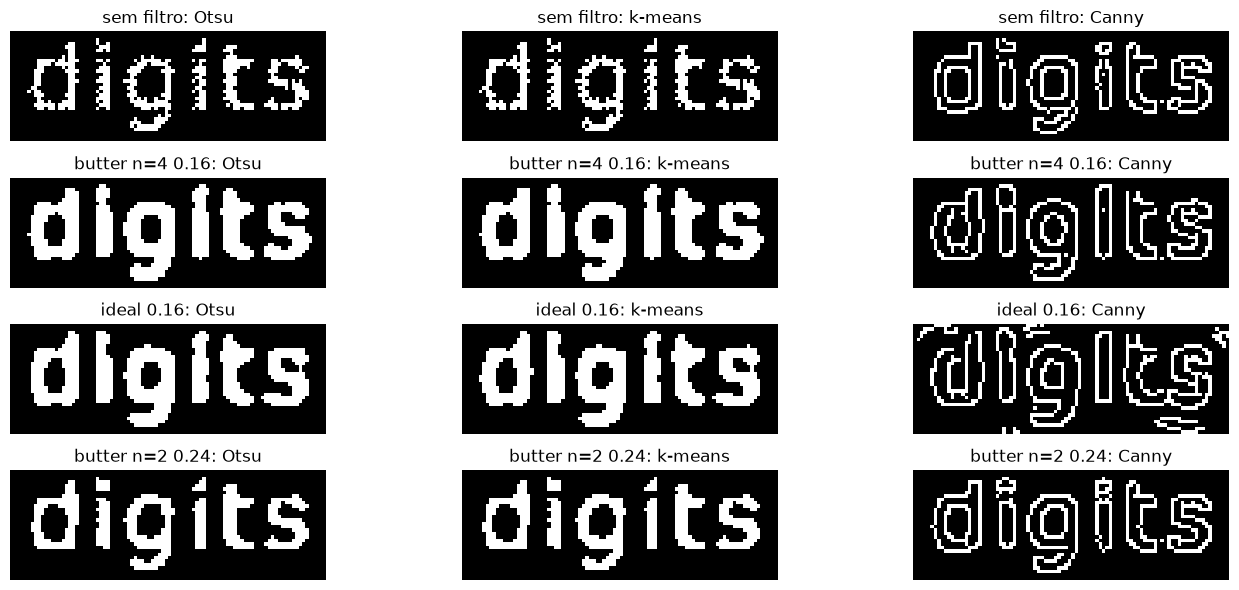

Recorte espaços internos ("define")


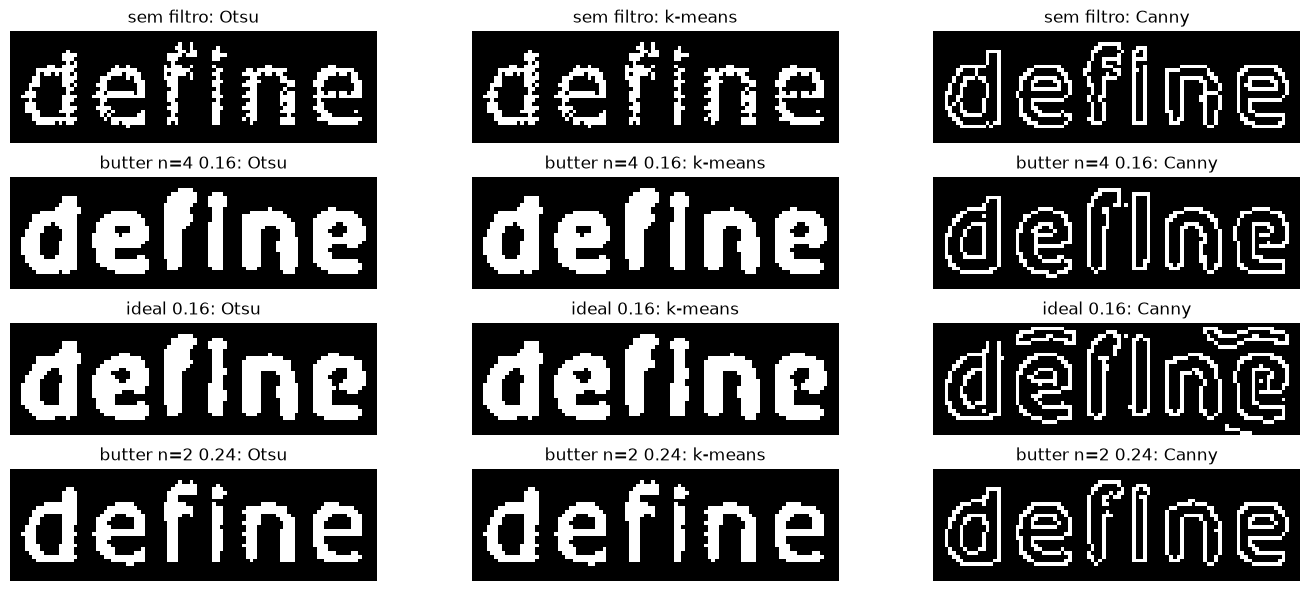

Recorte caracteres próximos ("ftware")


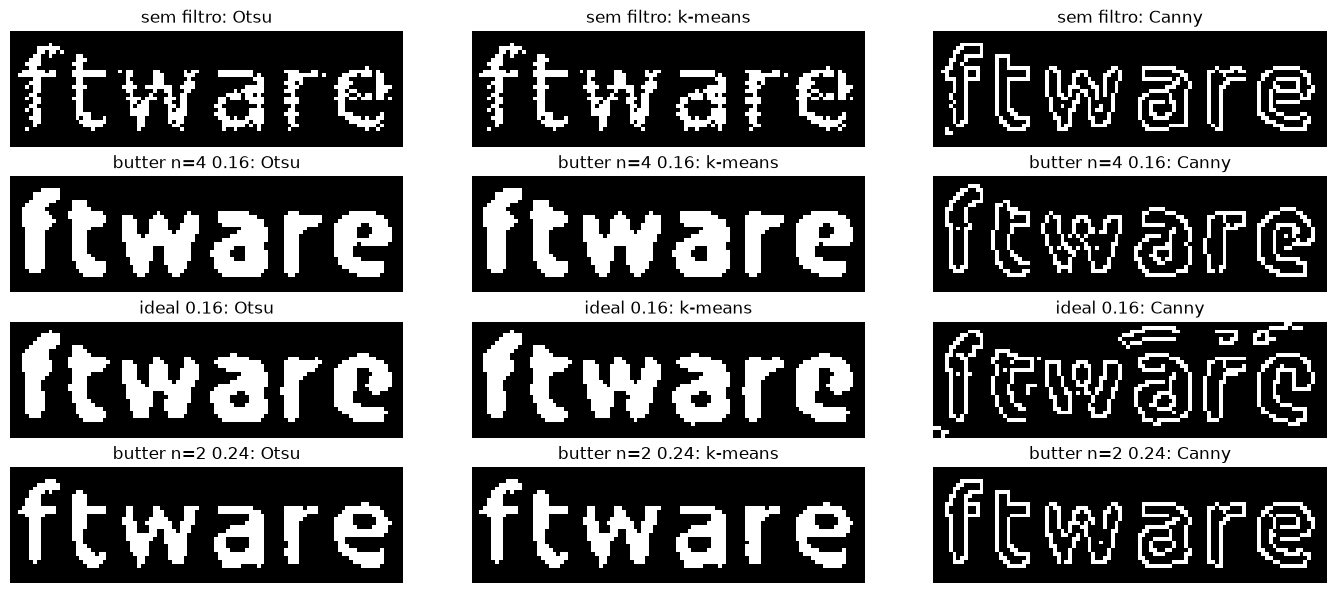

In [15]:
"""IMAGEM REAL: MELHORES CONFIGURAÇÕES DO SINTÉTICO x SEM FILTRO"""

escolhidas = list(dict.fromkeys(['sem filtro', melhores['otsu'], melhores['kmeans'], 'butter n=2 0.24']))
for nome_recorte, r in RECORTES.items():
    imagens, titulos = [], []
    for nome in escolhidas:
        s = seg_real[nome]
        imagens += [recortar(s['otsu'], r['caixa']), recortar(s['kmeans'], r['caixa']), recortar(s['canny'], r['caixa'])]
        titulos += [f'{nome}: Otsu', f'{nome}: k-means', f'{nome}: Canny']
    print(f'Recorte {nome_recorte}')
    painel(imagens, titulos, 3, figsize=(14, 1.5 * len(escolhidas)))

**Resposta**

Critério de equilíbrio (código acima): nenhuma união de caracteres, depois o menor número de fragmentos e, no desempate, o maior IoU.

| Segmentador | Sem filtro | Melhor equilíbrio no sintético | Imagem real (marcas, item 3) |
|---|---|---|---|
| Otsu | IoU 0,844; 57 fragmentos; 0% recuperado | `butter n=4 0.16`: IoU 0,708; 3 fragmentos; 69,5% recuperado; 0 uniões | `butter n=2 0.24`: 17/18 falhas fechadas, 98% dos espaços internos e 100% das separações |
| k-means | IoU 0,842; 57 fragmentos | `ideal 0.16`: IoU 0,706; 3 fragmentos; 71,5% recuperado (empata com `butter n=4 0.16`, IoU 0,705) | igual ao Otsu (64 px de diferença) |
| Canny | F1 0,999 | nenhuma filtragem supera; a melhor filtrada é `butter n=1 0.24` / `gauss 0.24` (F1 0,998) | contornos mais lisos com `butter n=2 0.24`, sem ringing |

**Qual método apresentou o melhor resultado sem filtragem?**
- Pelo F1 de bordas, a única métrica comum aos três, o **Canny**: 0,999, contra 0,992 do k-means e 0,991 do Otsu.
- Parte dessa vantagem vem do σ = 1 interno do Canny e da tolerância de 1,5 px, que não pune os contornos em volta das falhas.
- Nas regiões, Otsu e k-means são equivalentes (IoU 0,844 x 0,842) e mantêm todas as falhas. Na imagem real, os dois reproduzem a própria entrada.

**Qual combinação de filtro, parâmetros e segmentador reduziu melhor as falhas?**
- **No sintético:** Butterworth n=4 com f_c = 0,16 + Otsu. Os fragmentos caem de 57 para 3 e a recuperação sobe de 0% para 69,5%, sem unir caracteres. O ideal 0,16 + k-means fica praticamente empatado (71,5%).
- Recuperações maiores (até 95%) só aparecem com f_c ≤ 0,10, que já une caracteres.
- **Na imagem real:** Butterworth n=2 com f_c = 0,24 + Otsu fecha 17 das 18 falhas marcadas.

**A redução das falhas provocou engrossamento de traços, perda de espaços internos ou união de caracteres?**
- **Engrossamento:** sempre. Os falsos positivos vão de 1,1% para 32,4% no sintético, e a área de texto da imagem real vai de 7,9% para 9,8%, chegando a 22% com f_c = 0,06. A causa é o limiar do Otsu subir para 0,6–0,85 na imagem suavizada.
- **Espaços internos:** o melhor caso sintético perde 17% da área interna. Com f_c ≤ 0,10, os olhos do "e" e do "a" fecham.
- **União:** nenhuma com f_c ≥ 0,16 (exceto `butter n=2 0.16`, com 1); 1 a 4 uniões com f_c = 0,10 e 8 a 10 com f_c = 0,06.

**O melhor resultado de PSNR/SSIM também apresentou a melhor segmentação?**
- **Não.** O maior PSNR é o `butter n=4 0.24` (21,78 dB, empatado com `gauss 0.24` e `butter n=2 0.24`), e o maior SSIM é o `butter n=2 0.24` (0,937).
- São filtros leves, que removem o ruído e quase não mexem nas falhas: 22–23 fragmentos e 16–21% de recuperação. A configuração de melhor equilíbrio tem PSNR menor (20,49 dB).
- PSNR e SSIM medem a fidelidade da intensidade, dominada pelo fundo e pelo ruído, e não a topologia da máscara.

**Em quais situações a filtragem piorou o resultado?**
- **f_c = 0,06 (todos os filtros):** 8 a 10 uniões, espaços internos entre 17% e 40% e IoU entre 0,35 e 0,47. Na imagem real, as palavras viram manchas.
- **f_c = 0,10:** 1 a 4 uniões. Na imagem real, "ft" e "tw" se tocam e os "e" fecham.
- **Filtro ideal:** o ringing derruba o F1 do Canny (0,31; 0,54 e 0,73 para f_c = 0,06; 0,10 e 0,16), e cria contornos extras na imagem real. O ideal e o Butterworth n=4, que se aproxima dele, também geram espaços internos falsos (13 em f_c = 0,10, para uma referência de 11).
- **IoU/Dice e F1 do Canny:** todas as filtragens ficaram abaixo da entrada sem filtro.

**Melhor configuração deste experimento x configuração para outras imagens**
- **O ótimo não é um f_c universal.** Ele depende, em pixels, da largura da falha, da espessura do traço e do espaçamento entre letras.
  - No sintético, as faixas atravessam o traço inteiro (algumas com 2 px) em traços de ≈4 px, e o equilíbrio ficou em f_c = 0,16.
  - Na imagem real, as falhas são de 1–2 px em traços de 2–3 px com letras a 2–4 px, e f_c = 0,24 já basta; 0,16 encolhe os olhos dos "e".
  - Em outra resolução, o corte precisa ser recalibrado: com o dobro de pixels por letra, o f_c equivalente cai pela metade.
- **O que tende a valer em outras imagens:**
  - Evitar o ideal (ringing) e preferir Butterworth n=2 ou gaussiano.
  - Escolher o corte pelo σ espacial equivalente (σ ≈ 1/(2π f_c)): da ordem da largura das falhas e bem menor que o espaçamento entre caracteres.
  - Lembrar que, na imagem suavizada, o Otsu sobe o limiar e engrossa os traços.